# IAM word handwriting recognition and semantic search

Uses only your attached IAM dataset. No line images, `lines.txt`, `forms.txt`, Washington data, or artificial images are required.

- IAM word images are discovered recursively under `/kaggle/input` (or `CFG['iam_dir']`).
- Existing `words.txt` or CSV/TSV word labels are optional and auto-detected. Without labels, the notebook runs pretrained OCR and exports predictions; supervised experiments are skipped.
- With labels, the original baseline, two-stage training, decoding, correction and search experiments run on **word crops**. Forms are disjoint across splits; writer independence is unknown without writer metadata. This is a custom split, not an official IAM benchmark.
- `FAST_DEBUG=True` is a smoke test. Set it to `False` for full experiments. Enable a Kaggle GPU and Internet for model downloads, or configure local model folders.
- Restart the kernel and **Run All** after replacing the notebook. Outputs: `/kaggle/working/results_iam`.

**v2 accuracy changes**
1. `FAST_DEBUG=True` (default) is the same size as the original smoke test (1,024 / 128 / 128 words). `False` uses all words (~4-5 h).
2. Labels no longer start with `<s>`: the decoder is trained in the same format it was pretrained in (decoder start -> text -> `</s>`).
3. Label smoothing 0.1, larger effective batch (32), higher stage-2 LR (3e-5), stronger augmentation (shear, stroke-width, random margins).
4. Pre-processed images are computed once in parallel and cached on disk; DataLoader uses worker processes.
5. New section 6.5: n-best lexicon rescoring (beam candidates that are dictionary words get a bonus tuned on validation).
6. Label diagnostics in section 2 (status counts from `words.txt`).

## 1. Setup
Installs (only what is missing), versions, GPU check and fixed seeds. Kaggle already ships `torch`, `transformers`, `opencv`, `scikit-image`; we add `jiwer`, `rapidfuzz`, `rank-bm25`, `faiss-cpu` (and `sentence-transformers` if absent).

In [1]:
%pip install -q "transformers==4.57.1" sentencepiece

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ---- 1.1 Environment, installs, imports -------------------------------------------------
import os, sys, re, json, time, math, random, shutil, gc, warnings, subprocess, importlib, inspect, dataclasses
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          # one GPU keeps Trainer / generate() simple and deterministic
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"; os.environ["WANDB_MODE"] = "disabled"
warnings.filterwarnings("ignore")

def ensure(import_name, pip_name=None):
    """pip-install a package only if it cannot be imported (needs Internet ON in Kaggle)."""
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name or import_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])

for imp, pip in [("jiwer", "jiwer"), ("rapidfuzz", "rapidfuzz"), ("rank_bm25", "rank-bm25"), ("faiss", "faiss-cpu"),
                 ("sentence_transformers", "sentence-transformers"), ("skimage", "scikit-image"), ("cv2", "opencv-python-headless")]:
    ensure(imp, pip)

from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import transformers, jiwer, cv2, skimage, faiss, rapidfuzz, sentence_transformers, scipy
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

def pkg_version(*names):
    from importlib import metadata
    for n in names:
        try: return metadata.version(n)
        except Exception: pass
    return "n/a"

VERSIONS = {"python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
            "jiwer": pkg_version("jiwer"), "sentence-transformers": sentence_transformers.__version__,
            "faiss": pkg_version("faiss-cpu", "faiss-gpu", "faiss"), "opencv": cv2.__version__, "scikit-image": skimage.__version__,
            "rapidfuzz": rapidfuzz.__version__, "rank-bm25": pkg_version("rank-bm25", "rank_bm25"),
            "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "Pillow": Image.__version__}
display(pd.DataFrame({"package": list(VERSIONS), "version": list(VERSIONS.values())}).set_index("package").T)

package,python,torch,transformers,jiwer,sentence-transformers,faiss,opencv,scikit-image,rapidfuzz,rank-bm25,numpy,pandas,scipy,Pillow
version,3.13.15,2.11.0+cu128,4.57.1,4.0.0,5.7.0,1.15.1,4.14.0,0.25.2,3.14.6,0.2.2,2.1.3,2.3.3,1.16.3,13.0.0


In [3]:
# ---- 1.2 GPU check + fixed seeds ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory/2**30:.1f} GiB | CUDA {torch.version.cuda}")
else:
    print("WARNING: no GPU detected - fine-tuning TrOCR on CPU is impractically slow. "
          "Enable Settings -> Accelerator -> GPU, or use FAST_DEBUG=True just to test the code.")

def set_all_seeds(seed: int):
    """Seed python / numpy / torch / transformers (also sets cuDNN to deterministic mode)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_all_seeds(42)

GPU: Tesla T4 | 14.6 GiB | CUDA 12.8


In [4]:
# ---- 1.3 Configuration (edit here) -------------------------------------------------------
FAST_DEBUG = True      # True = tiny smoke test (same size as the original: 1024 / 128 / 128 words). False = all words (~4-5 h)

CFG = dict(
    seed=42, extra_seeds=[1337, 2024], run_multiseed=False,  # True = +2 full trainings (needs a second Kaggle session's worth of GPU time)
    run_ablation_retrain=False,         # True = +1 full training (raw vs pre-processed, clean ablation)
    run_crnn=True,                      # small CRNN baseline (~15-20 min on full data)
    keep_err_words=False,               # True = also use words.txt entries flagged 'err' (more data, noisier crops)
    split_mode="page",  # custom form-disjoint split; not an official benchmark split
    iam_words_txt=None, iam_labels_csv=None, inference_limit=100,
    official_splits=None,  # optional dict: train/val/test -> path or list of paths
    split_seed=0, split_val=0.15, split_test=0.15,           # fixed form split, independent of training seeds
    iam_dir=None,          # optionally force a folder under /kaggle/input; None = auto-discover
    trocr_id="microsoft/trocr-base-stage1", trocr_local=None,
    resume_from="/kaggle/working/results_iam/trocr_finetuned",
    # NOTE: "microsoft/trocr-base-handwritten" is already fine-tuned on IAM lines and scores much better out of the box,
    # but its training forms overlap this custom split, so its test numbers would be optimistic (leakage).
    minilm_id="sentence-transformers/all-MiniLM-L6-v2", minilm_local=None,
    target_h=128, max_label_len=32,     # pre-processing target height; max decoder length (tokens)
    batch_size=8, grad_accum=4, eval_batch_size=32,          # effective batch 32; if CUDA OOM use batch_size=4, grad_accum=8
    stage1_epochs=2,  stage1_lr=5e-5, stage1_patience=1,     # stage 1: encoder FROZEN (decoder adapts to IAM)
    stage2_epochs=10, stage2_lr=1e-5, stage2_patience=3,     # stage 2: everything unfrozen
    weight_decay=0.01, warmup_ratio=0.05, label_smoothing=0.1, augment=True,
    train_eval_limit=2000,              # val words used for the per-epoch CER during training (all selection later uses full val)
    num_workers=4,                      # DataLoader / pre-processing workers (Kaggle gives 4 CPUs)
    beams=[1, 2, 4, 8],
    nbest_beams=8, lexicon_bonus_grid=[0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0],   # section 6.5
    crnn_epochs=30, crnn_lr=1e-3, crnn_bs=32, crnn_h=64, crnn_maxw=1200,
    search_scope="test",                # "test" = index only held-out pages' OCR (honest); "all" = whole archive
    passage_lines=30,                    # a search "document" = this many consecutive lines
    save_model=True,
    debug_limit=None,
)
if FAST_DEBUG:
    CFG.update(
        extra_seeds=[],
        run_multiseed=False,
        run_ablation_retrain=False,
        stage1_epochs=2,
        stage2_epochs=3,
        crnn_epochs=2,
        run_crnn=False,
        beams=[1, 2],
        nbest_beams=4,
        debug_limit=dict(train=4096, val=128, test=128)
    )

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
RES, FIGS = WORK / "results_iam", WORK / "results_iam" / "figures"
TMP = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else Path("/tmp")   # big trainer checkpoints go here (not saved as output)
for d in (RES, FIGS, TMP): d.mkdir(parents=True, exist_ok=True)
MAXLEN = CFG["max_label_len"]

RESULTS = {"meta": {"versions": VERSIONS, "config": CFG, "fast_debug": FAST_DEBUG,
                    "device": str(device), "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None},
           "configs": {}, "val": {}, "decoding": [], "post_correction": {}, "ablation": [], "seeds": [], "search": {}, "demo": {}}
PRED_STORE = {}     # config name -> {"preds": [...], "conf": [...] or None}  (test split)

def _jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (Path,)): return str(o)
    return str(o)

def save_results():
    with open(RES / "results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=_jsonable)

def save_fig(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    return FIGS / f"{name}.png"

save_results()
print("Outputs ->", RES)

Outputs -> /kaggle/working/results_iam


## 2. IAM word data
Images alone are sufficient for OCR. Correct word transcriptions are necessary for training and CER/WER; filenames contain identifiers, not the correct text. Existing labels are used if available, with no requirement to attach additional files. CSV/TSV labels need an image/id column and a text/transcription column. Use `iam_labels_csv` if automatic discovery is ambiguous.

In [5]:
# Discover only IAM word images and optional labels.
IMG_EXT = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
IAM_WORD_ID = re.compile(r'^[a-z]\d{2}[a-z]?-\d{3}[a-z]?-\d{2}-\d{2}$')
INPUT_ROOT = Path(CFG['iam_dir'] or '/kaggle/input')
if not INPUT_ROOT.is_dir(): raise FileNotFoundError(f'IAM image folder not found: {INPUT_ROOT}')
ALL_IMGS, ALL_TXTS, LABEL_TABLES = [], [], []
for dp, dirs, names in os.walk(INPUT_ROOT):
    dirs.sort()
    for name in sorted(names):
        p = Path(dp) / name
        if p.suffix.lower() in IMG_EXT and IAM_WORD_ID.fullmatch(p.stem): ALL_IMGS.append(str(p))
        elif p.name.lower() == 'words.txt': ALL_TXTS.append(p)
        elif p.suffix.lower() in {'.csv', '.tsv'}: LABEL_TABLES.append(p)
img_map = {}
for p in ALL_IMGS:
    ident = Path(p).stem
    if ident in img_map: raise ValueError(f'Duplicate word image {ident}. Set iam_dir to one dataset folder.')
    img_map[ident] = p
if not img_map: raise FileNotFoundError(f'No extracted IAM word images found in {INPUT_ROOT}')
print(f'Found {len(img_map):,} IAM word images. No line/form metadata required.')

Found 115,320 IAM word images. No line/form metadata required.


In [6]:
# Optional ground truth already included in the IAM dataset.
labels, label_sources = {}, []
status_counts, no_image = Counter(), 0
def add_label(ident, text):
    ident = Path(str(ident).replace('\\', '/')).stem
    text = ' '.join(str(text).split())
    if ident not in img_map or not text: return
    if ident in labels and labels[ident] != text:
        raise ValueError(f'Conflicting labels for {ident}; select one label file in CFG.')
    labels[ident] = text

word_files = [Path(CFG['iam_words_txt'])] if CFG['iam_words_txt'] else ALL_TXTS
for p in word_files:
    before = len(labels)
    for line in p.read_text(errors='replace').splitlines():
        if not line.strip() or line.lstrip().startswith('#'): continue
        fields = line.strip().split(maxsplit=8)
        if len(fields) == 9 and IAM_WORD_ID.fullmatch(fields[0]):
            status_counts[fields[1]] += 1
            if fields[0] not in img_map:
                no_image += 1
            if fields[1] == 'ok' or CFG['keep_err_words']:
                add_label(fields[0], fields[8])
    if len(labels) > before: label_sources.append(str(p))
# Prefer official word labels; otherwise look for common tabular label formats.
tables = [Path(CFG['iam_labels_csv'])] if CFG['iam_labels_csv'] else ([] if labels else LABEL_TABLES)
for p in tables:
    try: table = pd.read_csv(p, sep='\t' if p.suffix.lower() == '.tsv' else ',', dtype=str, keep_default_na=False)
    except (pd.errors.ParserError, UnicodeError):
        if CFG['iam_labels_csv']: raise
        continue
    cols = {str(c).strip().lower(): c for c in table.columns}
    ic = next((cols[k] for k in ('id','image','image_id','image_path','filename','file_name','file','path') if k in cols), None)
    tc = next((cols[k] for k in ('text','transcription','transcript','label','word','ground_truth') if k in cols), None)
    if ic is None or tc is None:
        if CFG['iam_labels_csv']: raise ValueError(f'Need image/id and text/transcription columns in {p}')
        continue
    before = len(labels)
    for ident, text in zip(table[ic], table[tc]): add_label(ident, text)
    if len(labels) > before: label_sources.append(str(p))
HAS_LABELS = bool(labels)
rows, unreadable = [], []
# Images are NOT opened here (opening ~38k files from /kaggle/input takes 15+ min).
# Readability is checked later, only for the words each split actually uses.
for ident in sorted(labels if HAS_LABELS else img_map):
    p = img_map[ident]
    rows.append(dict(id=ident, page=ident.rsplit('-', 2)[0], text=labels.get(ident, ''), path=p))
DF = pd.DataFrame(rows)
if DF.empty: raise ValueError('No readable IAM word images remain.')
DATA_SOURCE = 'IAM words'
RESULTS['meta'].update(data_source=DATA_SOURCE, has_labels=HAS_LABELS, label_sources=label_sources,
    word_images=len(img_map), retained=len(DF), unreadable=len(unreadable), writer_disjoint=False)
if status_counts:
    print(f'words.txt entries by segmentation status: {dict(status_counts)} | entries without an image: {no_image:,}')
print(f'{len(DF):,} readable words; {DF.page.nunique()} forms; labels available: {HAS_LABELS}')
if not HAS_LABELS: print('Image-only mode: OCR predictions below; training and accuracy experiments are skipped.')
save_results()

words.txt entries by segmentation status: {'ok': 38305, 'err': 6259} | entries without an image: 0
38,305 readable words; 610 forms; labels available: True


In [7]:
# Image-only OCR: no transcript files required.
if not HAS_LABELS:
    from transformers import TrOCRProcessor, VisionEncoderDecoderModel
    source = CFG['trocr_local'] or 'microsoft/trocr-base-handwritten'
    ocr_processor = TrOCRProcessor.from_pretrained(source)
    ocr_model = VisionEncoderDecoderModel.from_pretrained(source).to(device).eval()
    limit = CFG['inference_limit']  # None = all images; default 100 for a quick first run
    selected = DF if limit is None else DF.head(limit)
    predictions = []
    for start in tqdm(range(0, len(selected), CFG['eval_batch_size']), desc='IAM word OCR'):
        batch = selected.iloc[start:start + CFG['eval_batch_size']]
        images = []
        for path in batch.path:
            with Image.open(path) as im: images.append(im.convert('RGB'))
        pixels = ocr_processor(images=images, return_tensors='pt').pixel_values.to(device)
        with torch.inference_mode():
            ids = ocr_model.generate(pixels, max_new_tokens=CFG['max_label_len'], num_beams=1)
        predictions.extend(ocr_processor.batch_decode(ids, skip_special_tokens=True))
    output = selected[['id','page','path']].copy()
    output['prediction'] = predictions
    output.to_csv(RES / 'iam_word_predictions.csv', index=False)
    display(output.head(20))
    RESULTS['meta'].update(inference_model=source, predicted_words=len(output))
    save_results()
    print('Saved', RES / 'iam_word_predictions.csv')
    print('No ground truth provided: no training or accuracy scores were produced.')


In [8]:
if HAS_LABELS:
    from itertools import combinations
    from functools import lru_cache
    val_frac, test_frac = CFG['split_val'], CFG['split_test']
    if not (0 < val_frac < 1 and 0 < test_frac < 1 and val_frac + test_frac < 1):
        raise ValueError('Invalid split fractions')
    pages = np.array(sorted(DF.page.unique()))
    np.random.RandomState(CFG['split_seed']).shuffle(pages)
    nt, nv = max(1, round(test_frac * len(pages))), max(1, round(val_frac * len(pages)))
    if len(pages) <= nt + nv: raise ValueError('Need at least three forms for train/validation/test.')
    groups = dict(test=pages[:nt], val=pages[nt:nt+nv], train=pages[nt+nv:])
    SPLITS = {k: DF[DF.page.isin(groups[k])].copy() for k in ('train', 'val', 'test')}
    for a, b in combinations(SPLITS, 2):
        for key in ('id', 'page'): assert set(SPLITS[a][key]).isdisjoint(SPLITS[b][key])
    for k, d in SPLITS.items():
        if CFG['debug_limit']:
            limit = min(CFG['debug_limit'][k], len(d))
    
            # Shuffle within each split, then take words across forms.
            d = d.sample(frac=1, random_state=CFG['split_seed']).copy()
            d['_position'] = d.groupby('page').cumcount()
            d = (
                d.sort_values('_position', kind='stable')
                 .head(limit)
                 .drop(columns='_position')
                 .sort_values('id')
            )
        ok_mask = []
        for p in d.path:
            try:
                with Image.open(p) as im:
                    im.load()
                ok_mask.append(True)
            except (OSError, ValueError):
                ok_mask.append(False)
        n_bad = len(ok_mask) - sum(ok_mask)
        if n_bad:
            print(f'{k}: skipped {n_bad} unreadable images')
            unreadable.extend(d.id[[not x for x in ok_mask]].tolist())
        d = d[ok_mask]
        if len(d) < 5: raise ValueError(f'Too few labelled words in {k}: {len(d)}')
        SPLITS[k] = d.reset_index(drop=True)
    train_df, val_df, test_df = [SPLITS[k] for k in ('train', 'val', 'test')]
    train_refs, val_refs, test_refs = [d.text.tolist() for d in (train_df, val_df, test_df)]
    RESULTS['meta']['unreadable'] = len(unreadable)
    RESULTS['meta']['split_protocol'] = 'custom form-disjoint; writer identities unknown'
    RESULTS['meta']['split'] = {k: dict(pages=sorted(d.page.unique()), words=len(d)) for k,d in SPLITS.items()}
    manifest = pd.concat([d.assign(split=k) for k,d in SPLITS.items()], ignore_index=True)
    manifest.to_csv(RES / 'iam_split_manifest.csv', index=False)
    print('Custom form-disjoint split; writer overlap cannot be checked.')
    display(manifest.groupby('split').agg(words=('id','size'), forms=('page','nunique')))
    @lru_cache(maxsize=32)
    def load_raw(path):
        with Image.open(path) as im: return im.convert('L')
    save_results()

Custom form-disjoint split; writer overlap cannot be checked.


,words,forms
split,,
test,128,92
train,4096,426
val,128,92


,pages,lines,words,chars,chars/line,unique words,OOV rate vs train vocab (%),mean img w x h
split,,,,,,,,
train,426,4096,3633,17792,4.34,1524,0.00,166 x 71
val,92,128,119,511,3.99,94,24.37,153 x 76
test,92,128,116,610,4.77,97,37.93,183 x 79


Charset size (train): 74 | train-vocab size: 1524
NOTE: the OOV rate bounds how much a training-transcript dictionary can help in post-correction (section 7).


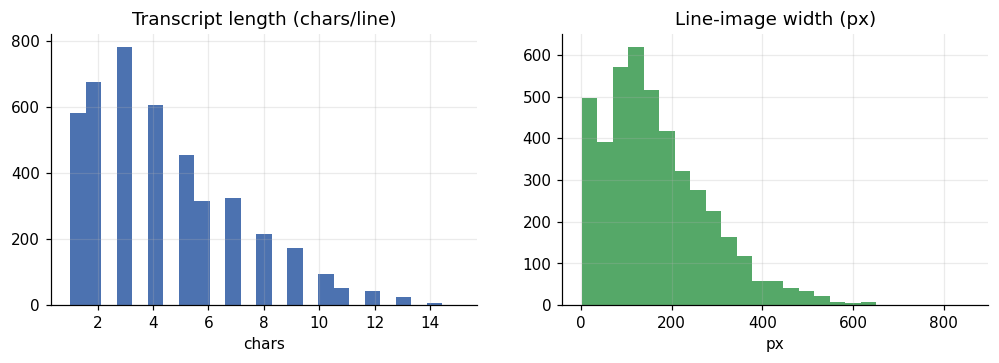

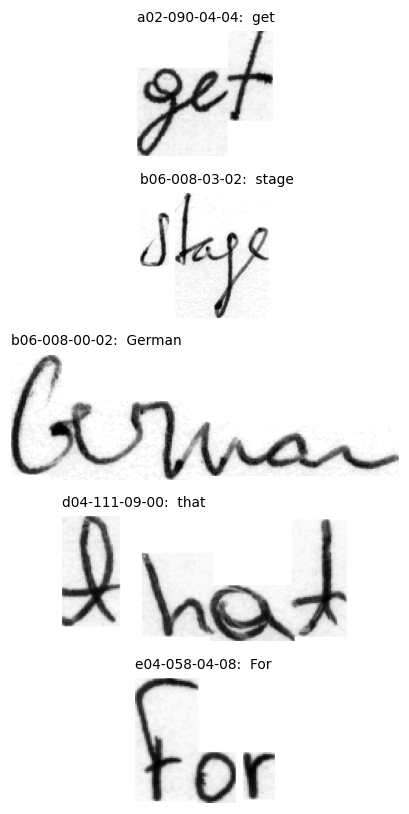

In [9]:
if HAS_LABELS:
    # ---- 2.4 Dataset statistics + 5 sample images -------------------------------------------
    def norm_words(text): return [re.sub(r"^\W+|\W+$", "", w).lower() for w in text.split() if re.sub(r"^\W+|\W+$", "", w)]
    train_vocab = set(w for t in train_refs for w in norm_words(t))

    rows = []
    for name, d in SPLITS.items():
        sizes = np.array([load_raw(p).size for p in d.path])        # (w, h)
        words = [w for t in d.text for w in norm_words(t)]
        oov = np.mean([w not in train_vocab for w in words]) if name != "train" else 0.0
        rows.append({"split": name, "pages": d.page.nunique(), "lines": len(d), "words": len(words), "chars": int(d.text.str.len().sum()),
                     "chars/line": d.text.str.len().mean(), "unique words": len(set(words)), "OOV rate vs train vocab (%)": 100 * oov,
                     "mean img w x h": f"{sizes[:,0].mean():.0f} x {sizes[:,1].mean():.0f}"})
    stats_df = pd.DataFrame(rows).set_index("split"); display(stats_df.round(2))
    RESULTS["meta"]["dataset_stats"] = stats_df.reset_index().to_dict("records")
    print(f"Charset size (train): {len(set(''.join(train_refs)))} | train-vocab size: {len(train_vocab)}")
    print("NOTE: the OOV rate bounds how much a training-transcript dictionary can help in post-correction (section 7).")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    USED = pd.concat(list(SPLITS.values()), ignore_index=True)   # only the words in use (not all of DF)
    ax[0].hist(USED.text.str.len(), bins=25, color="#4C72B0"); ax[0].set(title="Transcript length (chars/line)", xlabel="chars")
    ax[1].hist([load_raw(p).size[0] for p in USED.path], bins=25, color="#55A868"); ax[1].set(title="Line-image width (px)", xlabel="px")
    save_fig(fig, "dataset_stats"); plt.show()

    rng = np.random.RandomState(0); idx = rng.choice(len(train_df), 5, replace=False)
    fig, axes = plt.subplots(5, 1, figsize=(11, 7.5))
    for a, i in zip(axes, idx):
        a.imshow(load_raw(train_df.path[i]), cmap="gray"); a.axis("off"); a.set_title(f"{train_df.id[i]}:  {train_df.text[i]}", fontsize=9, loc="left")
    fig.tight_layout(); save_fig(fig, "sample_lines"); plt.show()

## 3. Pre-processing
Three input variants are implemented and compared — **honestly, on the validation set** (section 4.2):

| mode | steps |
|---|---|
| `raw` | grayscale → RGB only (what the pretrained model saw) |
| `gray` | grayscale → polarity fix (dark ink on light paper) → **deskew** (projection-profile search over ±3°) → CLAHE contrast boost → resize to fixed height |
| `binarized` | as `gray`, but with **Sauvola** local-threshold binarisation instead of CLAHE (handles faded ink / stains better than a global threshold) |

Binarisation removes paper texture but also removes the grey-level anti-aliasing that TrOCR was pre-trained on, so it is *not* assumed to help — the data decides.

In [10]:
if HAS_LABELS:
    # ---- 3.1 Pre-processing functions ----------------------------------------------------------
    from skimage.filters import threshold_sauvola
    import multiprocessing as mp
    from concurrent.futures import ProcessPoolExecutor
    cv2.setNumThreads(0)                 # avoid OpenCV thread-pool issues inside forked workers
    PROC_MODES = ["raw", "gray", "binarized"]

    def _odd(n): n = int(n); return n if n % 2 else n + 1
    def ensure_dark_on_light(g): return 255 - g if g.mean() < 127 else g

    def estimate_skew(g, max_angle=3.0, step=0.5):
        """Deskew angle (deg) maximising the variance of the horizontal projection profile (classic text-line deskew)."""
        h, w = g.shape; s = 400.0 / max(h, w); small = cv2.resize(g, (max(8, int(w * s)), max(8, int(h * s))), interpolation=cv2.INTER_AREA)
        ink = cv2.threshold(small, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1].astype(np.float32)
        hh, ww = ink.shape; best, best_a = -1, 0.0
        for a in np.arange(-max_angle, max_angle + 1e-6, step):
            r = cv2.warpAffine(ink, cv2.getRotationMatrix2D((ww / 2, hh / 2), a, 1.0), (ww, hh))
            v = np.var(r.sum(1))
            if v > best: best, best_a = v, a
        return best_a

    def deskew(g):
        a = estimate_skew(g)
        if abs(a) < 0.25: return g, 0.0
        h, w = g.shape
        return cv2.warpAffine(g, cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0), (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE), a

    def resize_height(g, h):
        s = h / g.shape[0]; g = cv2.resize(g, (max(8, int(round(g.shape[1] * s))), h), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
        return cv2.copyMakeBorder(g, 6, 6, 12, 12, cv2.BORDER_CONSTANT, value=255)     # small white margin

    def preprocess(img, mode="gray", target_h=None):
        """PIL (any mode) -> RGB PIL ready for the TrOCR processor."""
        target_h = target_h or CFG["target_h"]
        if mode == "raw": return img.convert("RGB")
        g = ensure_dark_on_light(np.array(img.convert("L")))
        g, _ = deskew(g)
        if mode == "gray":
            g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(2, 8)).apply(g)
        elif mode == "binarized":
            th = threshold_sauvola(g, window_size=_odd(max(15, g.shape[0] // 4)), k=0.2)
            g = ((g > th) * 255).astype(np.uint8)
        else: raise ValueError(mode)
        return Image.fromarray(resize_height(g, target_h)).convert("RGB")

    # Pre-processing (deskew search + CLAHE/Sauvola) is CPU-heavy, so each image is processed ONCE
    # (in parallel) and cached as a grayscale PNG. Training epochs then only read small PNGs.
    PP_CACHE = TMP / f"pp_cache_h{CFG['target_h']}"

    def _cache_path(path, mode):
        return PP_CACHE / mode / (Path(path).stem + ".png")

    def _make_cached(job):
        path, mode = job
        out = _cache_path(path, mode)
        if out.exists():
            return 0
        out.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(path) as im:
            g = np.array(preprocess(im.convert("L"), mode).convert("L"))
        tmp = out.with_suffix(".tmp.png")
        cv2.imwrite(str(tmp), g)
        os.replace(tmp, out)             # atomic: readers never see a half-written file
        return 1

    def warm_cache(paths, mode):
        if mode == "raw":
            return
        (PP_CACHE / mode).mkdir(parents=True, exist_ok=True)
        todo = [(p, mode) for p in paths if not _cache_path(p, mode).exists()]
        if not todo:
            return
        workers = max(1, os.cpu_count() or 1)
        with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as ex:
            list(tqdm(ex.map(_make_cached, todo, chunksize=64), total=len(todo), desc=f"pre-processing [{mode}]", leave=False))

    def processed_image(path, mode):
        if mode == "raw":
            return load_raw(path).convert("RGB")
        out = _cache_path(path, mode)
        if not out.exists():
            _make_cached((path, mode))
        with Image.open(out) as im:
            return im.convert("RGB")

    class ImageSequence:
        """Load images on demand; slices return one inference batch."""
        def __init__(self, paths, mode): self.paths, self.mode = tuple(paths), mode
        def __len__(self): return len(self.paths)
        def __getitem__(self, index):
            if isinstance(index, slice):
                return [processed_image(p, self.mode) for p in self.paths[index]]
            return processed_image(self.paths[index], self.mode)

    def get_images(df, mode):
        paths = df.path.tolist()
        warm_cache(paths, mode)
        return ImageSequence(paths, mode)

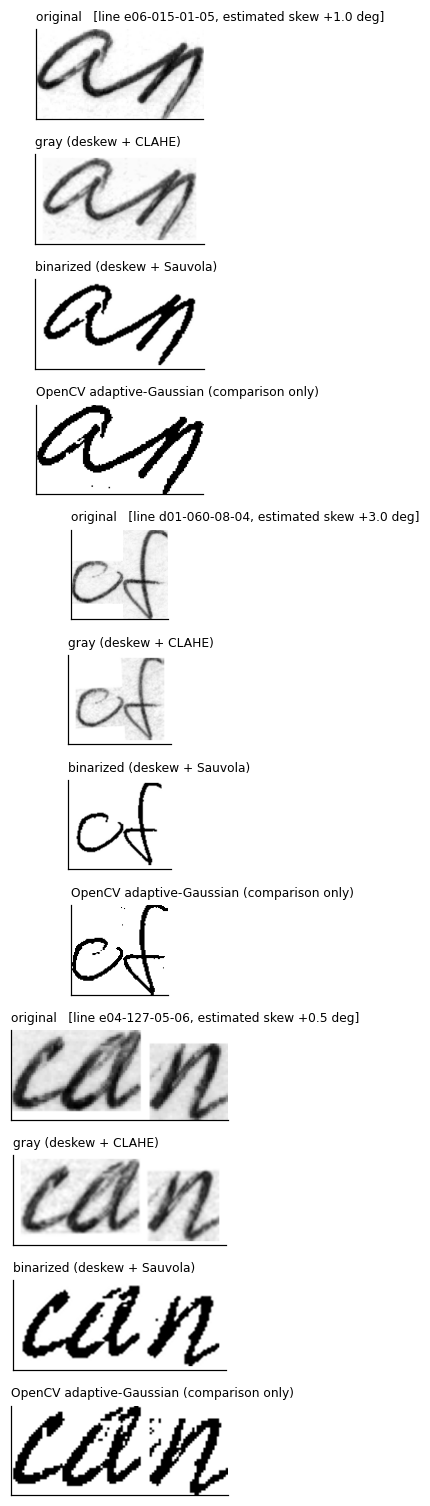

In [11]:
if HAS_LABELS:
    # ---- 3.2 Before / after ---------------------------------------------------------------------
    def adaptive_gaussian(img):
        g = ensure_dark_on_light(np.array(img.convert("L"))); g, _ = deskew(g)
        return cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, _odd(max(15, g.shape[0] // 3)), 10)

    sel = np.random.RandomState(1).choice(len(train_df), 3, replace=False)
    names = ["original", "gray (deskew + CLAHE)", "binarized (deskew + Sauvola)", "OpenCV adaptive-Gaussian (comparison only)"]
    fig, axes = plt.subplots(len(sel) * 4, 1, figsize=(12, 1.15 * len(sel) * 4))
    for r, i in enumerate(sel):
        img = load_raw(train_df.path[i]); _, ang = deskew(ensure_dark_on_light(np.array(img)))
        ims = [img, preprocess(img, "gray"), preprocess(img, "binarized"), Image.fromarray(adaptive_gaussian(img))]
        for c, im in enumerate(ims):
            a = axes[r * 4 + c]; a.imshow(im, cmap="gray"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
            a.set_title(names[c] + (f"   [line {train_df.id[i]}, estimated skew {ang:+.1f} deg]" if c == 0 else ""), fontsize=8, loc="left")
    fig.tight_layout(); save_fig(fig, "preprocessing_before_after"); plt.show()

## 4. Baseword crops — measured **before** any fine-tuning
Metrics are computed on the held-out **test pages** only after all settings have been chosen on validation. We report

* **CER** = (substitutions + deletions + insertions) / reference characters (corpus-level, spaces included),
* **WER** = the same at word level,
* **Exact-match** = % of word crops recognised perfectly (case-sensitive).

All generation settings are set explicitly (the TrOCR checkpoint ships with `length_penalty=2.0`, `no_repeat_ngram_size=3`, `num_beams=4` defaults that would silently change results): **greedy = 1 beam, no n-gram blocking, length-penalty 1.0**, and fp16 autocast on GPU for every configuration, so all rows are comparable.

In [12]:
if HAS_LABELS:
    # ---- 4.0 Metrics, model loading, generation helpers ---------------------------------------
    from rapidfuzz.distance import Levenshtein
    from transformers import (TrOCRProcessor, VisionEncoderDecoderModel, Seq2SeqTrainer, Seq2SeqTrainingArguments, EarlyStoppingCallback)

    def norm_ws(s): return " ".join(str(s).split())

    def score(refs, hyps):
        """Corpus-level CER / WER (jiwer) + exact-match line accuracy."""
        refs, hyps = [norm_ws(r) for r in refs], [norm_ws(h) for h in hyps]
        return dict(cer=float(jiwer.cer(refs, hyps)), wer=float(jiwer.wer(refs, hyps)),
                    exact=float(np.mean([r == h for r, h in zip(refs, hyps)])), n=len(refs))

    def line_stats(refs, hyps):
        """Per-line edit distance and reference length (for per-line CER, bootstrap CIs, risk-coverage)."""
        d = np.array([Levenshtein.distance(norm_ws(r), norm_ws(h)) for r, h in zip(refs, hyps)], dtype=float)
        l = np.array([max(1, len(norm_ws(r))) for r in refs], dtype=float)
        return d, l

    TROCR_SRC = CFG["trocr_local"] or CFG["trocr_id"]
    from transformers import AutoImageProcessor, RobertaTokenizer
    processor = TrOCRProcessor(
        image_processor=AutoImageProcessor.from_pretrained(TROCR_SRC, use_fast=False),
        tokenizer=RobertaTokenizer.from_pretrained(TROCR_SRC),
    )
    tokenizer = processor.tokenizer

    def set_generation_defaults(model):
        g = model.generation_config
        g.num_beams, g.no_repeat_ngram_size, g.length_penalty, g.early_stopping = 1, 0, 1.0, False
        g.max_length, g.max_new_tokens = MAXLEN, None

    def load_trocr(src=None):
        if src is None:
            src = TROCR_SRC
        m = VisionEncoderDecoderModel.from_pretrained(src)
        g = m.generation_config

        # Preserve checkpoint generation settings first.
        start = g.decoder_start_token_id
        if start is None:
            start = m.config.decoder_start_token_id
        if start is None:
            start = tokenizer.eos_token_id

        pad = g.pad_token_id
        if pad is None:
            pad = tokenizer.pad_token_id

        eos = g.eos_token_id
        if eos is None:
            eos = tokenizer.eos_token_id

        m.config.decoder_start_token_id = start
        m.config.pad_token_id = pad
        m.config.eos_token_id = eos

        g.decoder_start_token_id = start
        g.pad_token_id = pad
        g.eos_token_id = eos

        set_generation_defaults(m)
        return m.to(device)
    def _sync():
        if device.type == "cuda": torch.cuda.synchronize()

    @torch.no_grad()
    def sequence_confidence(model, pv, ids):
        """exp(mean token log-prob) of the generated sequence under the model (teacher-forced re-scoring)."""
        labels = ids[:, 1:].clone()                       # drop decoder-start token; the model shifts labels right itself
        pad = tokenizer.pad_token_id
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(pixel_values=pv, labels=labels).logits
        lp = torch.log_softmax(logits.float(), -1).gather(-1, labels.unsqueeze(-1)).squeeze(-1)
        mask = (labels != pad).float()
        return ((lp * mask).sum(1) / mask.sum(1).clamp(min=1)).exp().cpu().tolist()

    def beam_batch_size(num_beams):
        """Fewer images per batch for wide beams (keeps beam x batch x cross-attention cache inside T4 memory)."""
        if num_beams <= 1:
            return CFG["eval_batch_size"]
        return max(4, (2 * CFG["eval_batch_size"]) // num_beams)

    @torch.no_grad()
    def predict(model, images, num_beams=1, batch_size=None, with_conf=False, desc=""):
        """Returns (texts, confidences|None, seconds spent inside generate())."""
        model.eval(); texts, confs, t_gen = [], [], 0.0
        bs = batch_size
        if bs is None:
            bs = beam_batch_size(num_beams)
        for i in tqdm(range(0, len(images), bs), desc=desc, leave=False):
            pv = processor(images=images[i:i + bs], return_tensors="pt").pixel_values.to(device)
            _sync(); t0 = time.perf_counter()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                ids = model.generate(pv, num_beams=num_beams, max_length=MAXLEN, do_sample=False, early_stopping=num_beams > 1,
                                     no_repeat_ngram_size=0, length_penalty=1.0)
            _sync(); t_gen += time.perf_counter() - t0
            texts += [norm_ws(t) for t in tokenizer.batch_decode(ids, skip_special_tokens=True)]
            if with_conf: confs += sequence_confidence(model, pv, ids)
        return texts, (confs if with_conf else None), t_gen

    def run_eval(model, images, refs, num_beams=1, with_conf=False, desc="eval"):
        preds, confs, t = predict(model, images, num_beams, with_conf=with_conf, desc=desc)
        m = score(refs, preds); m.update(sec_per_line=t / max(1, len(images)), num_beams=num_beams)
        return m, preds, confs

    def record(name, preds, confs=None, sec_per_line=None, **extra):
        """Score TEST predictions, store them, and print one line."""
        m = score(test_refs, preds); m.update(extra)
        if sec_per_line is not None: m["sec_per_line"] = sec_per_line
        RESULTS["configs"][name] = m; PRED_STORE[name] = {"preds": list(preds), "conf": confs}
        print(f"[TEST] {name:<55s} CER {100*m['cer']:6.2f}%  WER {100*m['wer']:6.2f}%  exact {100*m['exact']:5.1f}%")
        save_results(); return m

### 4.1 Pretrained TrOCR (IAM) on the archive — raw input

In [13]:
if HAS_LABELS:
    BASE_MODEL = load_trocr()
        # Diagnose on validation images, not the test set.
    probe = val_df.sample(
        n=min(8, len(val_df)),
        random_state=CFG['seed'],
    )

    BASE_MODEL.eval()
    pixels = processor(
        images=list(get_images(probe, "raw")),
        return_tensors="pt",
    ).pixel_values.to(device)

    # Full precision here helps isolate generation problems.
    with torch.inference_mode():
        token_ids = BASE_MODEL.generate(
            pixels,
            max_length=MAXLEN,
            num_beams=1,
            do_sample=False,
        )

    decoded = tokenizer.batch_decode(
        token_ids, skip_special_tokens=True
    )

    display(pd.DataFrame({
        "correct text": probe.text.tolist(),
        "prediction": [repr(x) for x in decoded],
        "first token IDs": [
            row[:10].tolist() for row in token_ids
        ],
    }))

    print(
        "Decoder start:",
        BASE_MODEL.generation_config.decoder_start_token_id,
        "| EOS:",
        BASE_MODEL.generation_config.eos_token_id,
    )
    print(
        "Blank predictions:",
        sum(not x.strip() for x in decoded),
        "/", len(decoded),
    )
    print(f"TrOCR params: {sum(p.numel() for p in BASE_MODEL.parameters())/1e6:.0f} M "
          f"(encoder {sum(p.numel() for p in BASE_MODEL.encoder.parameters())/1e6:.0f} M, decoder {sum(p.numel() for p in BASE_MODEL.decoder.parameters())/1e6:.0f} M)")

    NAME_BASE = "Pretrained TrOCR (raw input, greedy)"
    m, p, c = run_eval(BASE_MODEL, get_images(test_df, "raw"), test_refs, 1, with_conf=True, desc="baseline/test")
    record(NAME_BASE, p, c, sec_per_line=m["sec_per_line"], stage="baseline")

    show = pd.DataFrame({"ground truth": test_refs[:6], "pretrained TrOCR": p[:6]})
    display(show.style.set_properties(**{"text-align": "left"}))

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-stage1 and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,correct text,prediction,first token IDs
0,or,'O',"[2, 673, 2, 1, 1]"
1,best,'best',"[2, 7885, 2, 1, 1]"
2,has,'has',"[2, 7333, 2, 1, 1]"
3,war,'war',"[2, 5557, 2, 1, 1]"
4,C.,'C.',"[2, 347, 4, 2, 1]"
5,How,'How',"[2, 6179, 2, 1, 1]"
6,enormous,'enormous',"[2, 225, 8693, 1827, 2]"
7,unto,'uy to',"[2, 5781, 7, 2, 1]"


Decoder start: 2 | EOS: 2
Blank predictions: 0 / 8
TrOCR params: 385 M (encoder 87 M, decoder 298 M)


baseline/test:   0%|          | 0/4 [00:00<?, ?it/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


[TEST] Pretrained TrOCR (raw input, greedy)                    CER  19.34%  WER  50.78%  exact  59.4%


,ground truth,pretrained TrOCR
0,be,le
1,put,TEL
2,Mr.,Mr.
3,chief,chief
4,",",1
5,the,the


### 4.2 Choose the pre-processing mode — on **validation** only
The same pretrained model reads the validation word crops under each pre-processing mode; the mode with the lowest **validation** CER becomes `MAIN_PREPROC` for fine-tuning, the CRNN, and the demo. (The ablation in section 8 re-tests this choice on the test set after fine-tuning.)

In [14]:
if HAS_LABELS:
    pre_rows = []
    for mode in PROC_MODES:
        mv, _, _ = run_eval(BASE_MODEL, get_images(val_df, mode), val_refs, 1, desc=f"val/{mode}")
        pre_rows.append({"mode": mode, "val CER (%)": 100 * mv["cer"], "val WER (%)": 100 * mv["wer"], "val exact (%)": 100 * mv["exact"]})
    pre_df = pd.DataFrame(pre_rows).set_index("mode"); display(pre_df.round(2))
    MAIN_PREPROC = pre_df["val CER (%)"].idxmin()
    print(f"-> MAIN_PREPROC = '{MAIN_PREPROC}' (lowest validation CER of the pretrained model)")
    RESULTS["meta"]["main_preproc"] = MAIN_PREPROC; RESULTS["val"]["pretrained_by_preproc"] = pre_df.reset_index().to_dict("records")

    NAME_BASE_PP = f"Pretrained TrOCR (+{MAIN_PREPROC}, greedy)"
    if MAIN_PREPROC != "raw":
        m, p, c = run_eval(BASE_MODEL, get_images(test_df, MAIN_PREPROC), test_refs, 1, with_conf=True, desc="baseline+pp/test")
        record(NAME_BASE_PP, p, c, sec_per_line=m["sec_per_line"], stage="baseline")
    else:
        NAME_BASE_PP = NAME_BASE      # identical configuration
    BASE_VAL = run_eval(BASE_MODEL, get_images(val_df, MAIN_PREPROC), val_refs, 1, desc="baseline/val")[0]   # epoch-0 point of the training curve

val/raw:   0%|          | 0/4 [00:00<?, ?it/s]

val/gray:   0%|          | 0/4 [00:00<?, ?it/s]

val/binarized:   0%|          | 0/4 [00:00<?, ?it/s]

,val CER (%),val WER (%),val exact (%)
mode,,,
raw,19.96,47.29,62.50
gray,19.96,44.96,63.28
binarized,17.03,41.09,66.41


-> MAIN_PREPROC = 'binarized' (lowest validation CER of the pretrained model)


baseline+pp/test:   0%|          | 0/4 [00:00<?, ?it/s]

[TEST] Pretrained TrOCR (+binarized, greedy)                   CER  18.52%  WER  46.88%  exact  60.9%


baseline/val:   0%|          | 0/4 [00:00<?, ?it/s]

### 4.3 Optional baseline: CRNN + CTC (SimpleHTR-style), trained briefly on the same IAM training pages
A small CNN → 2×BiLSTM → CTC network trained **from scratch** on the same training word crops (greedy CTC decoding). It is deliberately small and short — it shows what a classic HTR recipe gives with only a few hundred labelled word crops, versus transfer learning from a large pretrained model.

In [15]:
if HAS_LABELS:
    # ---- 4.3 CRNN + CTC baseline ----------------------------------------------------------------
    import copy
    CH = CFG["crnn_h"]
    CHARS = sorted(set("".join(train_refs))); C2I = {c: i + 1 for i, c in enumerate(CHARS)}; I2C = {i: c for c, i in C2I.items()}   # 0 = CTC blank

    class CRNN(nn.Module):
        def __init__(self, n_classes, hidden=256):
            super().__init__()
            def blk(i, o, pool): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(pool))
            self.cnn = nn.Sequential(blk(1, 32, (2, 2)), blk(32, 64, (2, 2)), blk(64, 128, (2, 1)), blk(128, 128, (2, 1)), blk(128, 256, (2, 1)))  # H/32, W/4
            self.rnn = nn.LSTM(256 * (CH // 32), hidden, num_layers=2, bidirectional=True, batch_first=True, dropout=0.3)
            self.drop, self.fc = nn.Dropout(0.3), nn.Linear(2 * hidden, n_classes)
        def forward(self, x):
            f = self.cnn(x)                                   # [B, C, H', W']
            b, c, h, w = f.shape
            f = f.permute(0, 3, 1, 2).reshape(b, w, c * h)    # [B, T, C*H']
            return self.fc(self.drop(self.rnn(f)[0]))         # [B, T, classes]

    class CRNNData(torch.utils.data.Dataset):
        def __init__(self, imgs, texts, train=False): self.imgs, self.texts, self.train = imgs, texts, train
        def __len__(self): return len(self.imgs)
        def __getitem__(self, i):
            g = np.array(self.imgs[i].convert("L")); w = int(round(g.shape[1] * CH / g.shape[0]))
            if self.train: w = int(w * random.uniform(0.9, 1.1))
            g = cv2.resize(g, (min(max(w, 64), CFG["crnn_maxw"]), CH), interpolation=cv2.INTER_AREA)
            if self.train:
                M = cv2.getRotationMatrix2D((g.shape[1] / 2, CH / 2), random.uniform(-2, 2), 1.0)
                g = cv2.warpAffine(g, M, (g.shape[1], CH), borderValue=255)
                g = np.clip(g.astype(np.float32) * random.uniform(0.85, 1.1) + random.uniform(-12, 12), 0, 255)
            x = torch.from_numpy(1.0 - g.astype(np.float32) / 255.0)[None]     # ink = high, background = 0
            y = torch.tensor([C2I[c] for c in self.texts[i] if c in C2I], dtype=torch.long)
            return x, y

    def crnn_collate(b):
        W = int(math.ceil(max(x.shape[2] for x, _ in b) / 4) * 4)
        X = torch.zeros(len(b), 1, CH, W)
        for i, (x, _) in enumerate(b): X[i, :, :, :x.shape[2]] = x
        return X, torch.tensor([x.shape[2] // 4 for x, _ in b]), torch.cat([y for _, y in b]), torch.tensor([len(y) for _, y in b])

    def ctc_greedy(logits, lens):
        best, out = logits.argmax(-1).cpu().numpy(), []
        for seq, l in zip(best, lens):
            s, prev = [], 0
            for k in seq[:int(l)]:
                if k != prev and k != 0: s.append(I2C[int(k)])
                prev = k
            out.append("".join(s))
        return out

    @torch.no_grad()
    def crnn_predict(model, imgs):
        model.eval(); dl = torch.utils.data.DataLoader(CRNNData(imgs, [""] * len(imgs)), batch_size=16, shuffle=False, collate_fn=crnn_collate)
        preds, t = [], 0.0
        for X, lens, _, _ in dl:
            _sync(); t0 = time.perf_counter(); lg = model(X.to(device)); _sync(); t += time.perf_counter() - t0
            preds += [norm_ws(s) for s in ctc_greedy(lg, lens)]
        return preds, t / len(imgs)

    def train_crnn():
        set_all_seeds(CFG["seed"])
        tr_imgs, va_imgs = get_images(train_df, MAIN_PREPROC), get_images(val_df, MAIN_PREPROC)
        dl = torch.utils.data.DataLoader(CRNNData(tr_imgs, train_refs, train=True), batch_size=CFG["crnn_bs"], shuffle=True, collate_fn=crnn_collate, drop_last=len(tr_imgs) > CFG["crnn_bs"], num_workers=CFG["num_workers"])
        model = CRNN(len(CHARS) + 1).to(device); opt = torch.optim.AdamW(model.parameters(), lr=CFG["crnn_lr"], weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["crnn_lr"], total_steps=CFG["crnn_epochs"] * len(dl))
        ctc = nn.CTCLoss(blank=0, zero_infinity=True); best, best_sd, hist = (9.0, None), None, []
        for ep in range(1, CFG["crnn_epochs"] + 1):
            model.train(); tot = 0.0
            for X, lens, y, ylen in dl:
                lp = model(X.to(device)).log_softmax(-1).transpose(0, 1)
                loss = ctc(lp, y.to(device), lens, ylen); opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sched.step(); tot += loss.item()
            if ep % 3 == 0 or ep == CFG["crnn_epochs"]:
                vc = jiwer.cer([norm_ws(r) for r in val_refs], crnn_predict(model, va_imgs)[0])
                hist.append(dict(epoch=ep, train_loss=tot / len(dl), val_cer=vc))
                if vc < best[0]: best, best_sd = (vc, ep), copy.deepcopy(model.state_dict())
        model.load_state_dict(best_sd); print(f"CRNN best val CER {100*best[0]:.2f}% at epoch {best[1]}")
        return model, pd.DataFrame(hist)

    NAME_CRNN = "CRNN+CTC baseline (from scratch, greedy)"
    if CFG["run_crnn"]:
        CRNN_MODEL, CRNN_HIST = train_crnn()
        cp, csec = crnn_predict(CRNN_MODEL, get_images(test_df, MAIN_PREPROC))
        record(NAME_CRNN, cp, None, sec_per_line=csec, stage="baseline")
        del CRNN_MODEL; gc.collect(); torch.cuda.empty_cache()
    else:
        print("CRNN baseline skipped (run_crnn=False)")

CRNN baseline skipped (run_crnn=False)


In [16]:
if HAS_LABELS:
    # ---- 4.4 IAM evaluation protocol (replaces the random IAM reference) ----
    RESULTS["meta"].pop("iam_reference", None)
    print("IAM is the main dataset. Section 4.1 already measures its held-out test baseline.")
    print("Initial model:", TROCR_SRC)
    print("Partition protocol:", CFG["split_mode"])
    print("All tuning must use validation; do not select settings from test results.")
    print("The default stage1 checkpoint is pre-trained only, before IAM task fine-tuning.")
    print("This experiment measures IAM handwriting recognition, not historical-archive generalisation.")
    save_results()

IAM is the main dataset. Section 4.1 already measures its held-out test baseline.
Initial model: microsoft/trocr-base-stage1
Partition protocol: page
All tuning must use validation; do not select settings from test results.
The default stage1 checkpoint is pre-trained only, before IAM task fine-tuning.
This experiment measures IAM handwriting recognition, not historical-archive generalisation.


### IAM protocol
The supervised baseline above uses the same held-out IAM word split. No separate dataset is loaded.

In [17]:
if HAS_LABELS:
    print('IAM-only word experiment: no separate reference dataset.')

IAM-only word experiment: no separate reference dataset.


## 5. Fine-tuning (two stages)
* **Stage 1 — encoder frozen** (lr 5e-5): only the text decoder adapts to the archive's vocabulary / orthography / punctuation, while the visual features stay intact.
* **Stage 2 — everything unfrozen** (lr 1e-5, cosine decay + warm-up): the vision encoder adapts to faded ink, historical letter-forms and the line geometry.
* `Seq2SeqTrainer`, **fp16**, evaluation after **every epoch** (val loss + **val CER** via generation), best-val-CER checkpoint restored, **early stopping** in both stages.
* On-the-fly augmentation on training word crops only (rotation/scale, shear, stroke width, random margins, brightness/contrast, blur).
* Labels are `[text tokens, </s>]` (no leading `<s>`), matching the pretrained decoder; label smoothing 0.1.
* Train/val loss and val CER per epoch are logged and plotted in section 9. The pretrained model's val CER is plotted as **epoch 0**.

In [18]:
if HAS_LABELS:
    # Check label lengths BEFORE training, using training/validation only.
    for split_name, texts in [("train", train_refs), ("val", val_refs)]:
        lengths = [len(tokenizer(t).input_ids) for t in texts]
        if max(lengths) > MAXLEN:
            raise ValueError(f"{split_name}: longest label has {max(lengths)} tokens; max_label_len={MAXLEN}. "
                             "Increase it in section 1.3 and rerun before training.")

    # ---- 5.1 Dataset, collator, metrics, training function ----------------------------------------
    DEC_START = BASE_MODEL.config.decoder_start_token_id
    PAD_ID, BOS_ID = tokenizer.pad_token_id, tokenizer.bos_token_id
    KERNEL = np.ones((2, 2), np.uint8)

    def augment_pil(img):
        """Handwriting augmentation: rotation/scale/shear (slant), stroke width, random margins, contrast, blur."""
        if random.random() < 0.1:
            return img                                      # keep some clean samples
        a = np.array(img); h, w = a.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-2.0, 2.0), random.uniform(0.9, 1.05))
        shear = random.uniform(-0.3, 0.3)                   # simulates different writing slant
        M[0, 1] += shear; M[0, 2] -= shear * h / 2
        a = cv2.warpAffine(a, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
        r = random.random()
        if r < 0.2:
            a = cv2.erode(a, KERNEL)                        # dark ink on light paper -> thicker strokes
        elif r < 0.4:
            a = cv2.dilate(a, KERNEL)                       # thinner strokes
        a = cv2.copyMakeBorder(a, random.randint(0, 10), random.randint(0, 10), random.randint(0, 24), random.randint(0, 24),
                               cv2.BORDER_CONSTANT, value=(255, 255, 255))
        a = np.clip(a.astype(np.float32) * random.uniform(0.8, 1.15) + random.uniform(-20, 20), 0, 255).astype(np.uint8)
        if random.random() < 0.25:
            a = cv2.GaussianBlur(a, (3, 3), 0)
        return Image.fromarray(a)

    class LineDataset(torch.utils.data.Dataset):
        def __init__(self, images, texts, augment=False): self.images, self.texts, self.augment = images, texts, augment
        def __len__(self): return len(self.images)
        def __getitem__(self, i):
            img = augment_pil(self.images[i]) if self.augment else self.images[i]
            pv = processor(images=img, return_tensors="pt").pixel_values[0]
            ids = tokenizer(self.texts[i], max_length=MAXLEN + 1, truncation=True).input_ids
            # Drop the leading <s>: the pretrained decoder goes straight from decoder-start (</s>) to text,
            # so labels must be [text tokens..., </s>] - otherwise fine-tuning first has to learn to emit <s>.
            if ids and ids[0] == BOS_ID:
                ids = ids[1:]
            ids = ids[:MAXLEN]
            labels = ids + [-100] * (MAXLEN - len(ids))
            return {"pixel_values": pv, "labels": torch.tensor(labels)}

    def collate_fn(b):
        labels = torch.stack([x["labels"] for x in b])
        # decoder inputs built explicitly so label smoothing works (Trainer removes `labels` before the forward pass)
        dec_in = torch.full_like(labels, PAD_ID)
        dec_in[:, 1:] = labels[:, :-1]
        dec_in[:, 0] = DEC_START
        dec_in[dec_in == -100] = PAD_ID
        return {"pixel_values": torch.stack([x["pixel_values"] for x in b]), "labels": labels, "decoder_input_ids": dec_in}

    def compute_metrics(eval_pred):
        preds, labels = eval_pred.predictions, eval_pred.label_ids
        if isinstance(preds, tuple): preds = preds[0]
        preds, labels = np.where(preds < 0, tokenizer.pad_token_id, preds), np.where(labels == -100, tokenizer.pad_token_id, labels)
        p = [norm_ws(s) for s in tokenizer.batch_decode(preds, skip_special_tokens=True)]
        r = [norm_ws(s) for s in tokenizer.batch_decode(labels, skip_special_tokens=True)]
        return {"cer": jiwer.cer(r, p), "wer": jiwer.wer(r, p)}

    def make_args(**kw):
        """Version-tolerant Seq2SeqTrainingArguments (drops/renames args the installed transformers doesn't know)."""
        fields = {f.name for f in dataclasses.fields(Seq2SeqTrainingArguments)}
        if "eval_strategy" not in fields and "eval_strategy" in kw: kw["evaluation_strategy"] = kw.pop("eval_strategy")
        dropped = [k for k in kw if k not in fields]
        if dropped: print("  (ignored args unsupported by this transformers version:", dropped, ")")
        return Seq2SeqTrainingArguments(**{k: v for k, v in kw.items() if k in fields})

    def history_from_trainer(trainer, stage, offset):
        log = trainer.state.log_history
        tr = {int(round(e["epoch"])): e["loss"] for e in log if "loss" in e and "eval_loss" not in e}
        rows = []
        for e in log:
            if "eval_loss" in e:
                ep = int(round(e["epoch"]))
                rows.append(dict(stage=stage, epoch=offset + ep, train_loss=tr.get(ep, np.nan), val_loss=e["eval_loss"], val_cer=e["eval_cer"], val_wer=e["eval_wer"]))
        return pd.DataFrame(rows)

    def finetune(seed, preproc, tag="main"):
        """Two-stage fine-tuning. Returns (best model, per-epoch history DataFrame)."""
        set_all_seeds(seed)
        stages = [(1, CFG["stage1_epochs"], CFG["stage1_lr"], CFG["stage1_patience"], True),
                  (2, CFG["stage2_epochs"], CFG["stage2_lr"], CFG["stage2_patience"], False)]
        if CFG["resume_from"]:
            print(f"[{tag}] resuming from {CFG['resume_from']} (stage 1 skipped)")
            model = load_trocr(CFG["resume_from"])
            stages = stages[1:]
        else:
            model = load_trocr()
        train_ds = LineDataset(get_images(train_df, preproc), train_refs, augment=CFG["augment"])
        val_sub = val_df
        if CFG["train_eval_limit"] and len(val_df) > CFG["train_eval_limit"]:
            val_sub = val_df.sample(n=CFG["train_eval_limit"], random_state=CFG["split_seed"]).sort_values("id")
        val_ds = LineDataset(get_images(val_sub, preproc), val_sub.text.tolist(), augment=False)
        hist, offset = [], 0
        for stage, epochs, lr, pat, freeze in stages:
            for p_ in model.encoder.parameters(): p_.requires_grad = not freeze
            n_train = sum(p_.numel() for p_ in model.parameters() if p_.requires_grad)
            print(f"[{tag}] stage {stage}: {'encoder FROZEN' if freeze else 'ALL layers unfrozen'} | trainable params {n_train/1e6:.1f} M | lr {lr} | max {epochs} ep | patience {pat}")
            ckpt = TMP / f"ckpt_{tag}_s{stage}"; shutil.rmtree(ckpt, ignore_errors=True)
            args = make_args(output_dir=str(ckpt), per_device_train_batch_size=CFG["batch_size"], per_device_eval_batch_size=CFG["eval_batch_size"],
                             gradient_accumulation_steps=CFG["grad_accum"], learning_rate=lr, num_train_epochs=epochs, weight_decay=CFG["weight_decay"],
                             warmup_ratio=CFG["warmup_ratio"], lr_scheduler_type="cosine", fp16=USE_AMP,
                             label_smoothing_factor=CFG["label_smoothing"],
                             eval_strategy="epoch", save_strategy="epoch", save_total_limit=1, save_only_model=True,
                             load_best_model_at_end=True, metric_for_best_model="cer", greater_is_better=False, logging_strategy="epoch",
                             predict_with_generate=True, generation_max_length=MAXLEN, generation_num_beams=1, report_to="none",
                             seed=seed, data_seed=seed, dataloader_num_workers=CFG["num_workers"], remove_unused_columns=False)
            trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate_fn,
                                     compute_metrics=compute_metrics, callbacks=[EarlyStoppingCallback(early_stopping_patience=pat)])
            trainer.train()
            h = history_from_trainer(trainer, stage, offset); hist.append(h); offset = int(h.epoch.max()) if len(h) else offset
            model = trainer.model; del trainer; gc.collect(); torch.cuda.empty_cache(); shutil.rmtree(ckpt, ignore_errors=True)
        for p_ in model.parameters(): p_.requires_grad = True
        set_generation_defaults(model)
        return model, pd.concat(hist, ignore_index=True)

In [19]:
if HAS_LABELS:
    # ---- 5.2 Run the MAIN fine-tuning (seed = CFG['seed']) ------------------------------------------
    t0 = time.time()
    MODEL_FT, HIST = finetune(CFG["seed"], MAIN_PREPROC, tag="main")
    print(f"fine-tuning wall-time: {(time.time()-t0)/60:.1f} min")
    display(HIST.round(4))
    HIST.to_csv(RES / "training_history.csv", index=False); RESULTS["training_history"] = HIST.to_dict("records")

    NAME_FT = "Fine-tuned (greedy)"
    m, p, c = run_eval(MODEL_FT, get_images(test_df, MAIN_PREPROC), test_refs, 1, with_conf=True, desc="FT/test")
    record(NAME_FT, p, c, sec_per_line=m["sec_per_line"], stage="fine-tuned")
    FT_VAL = run_eval(MODEL_FT, get_images(val_df, MAIN_PREPROC), val_refs, 1, desc="FT/val")[0]
    RESULTS["val"]["fine_tuned_greedy"] = FT_VAL
    if CFG["save_model"]:
        best_file = RES / "best_val_cer.txt"
        prev = 1.0
        if best_file.exists():
            prev = float(best_file.read_text())
        if FT_VAL["cer"] < prev:
            MODEL_FT.save_pretrained(RES / "trocr_finetuned"); processor.save_pretrained(RES / "trocr_finetuned")
            best_file.write_text(str(FT_VAL["cer"]))
            print(f"Saved: val CER {100*FT_VAL['cer']:.2f}% beats previous best {100*prev:.2f}%")
        else:
            print(f"Not saved: val CER {100*FT_VAL['cer']:.2f}% is not better than {100*prev:.2f}%")
    save_results()

[main] resuming from /kaggle/working/results_iam/trocr_finetuned (stage 1 skipped)
[main] stage 2: ALL layers unfrozen | trainable params 384.9 M | lr 1e-05 | max 3 ep | patience 3


Epoch,Training Loss,Validation Loss,Cer,Wer
1,5.957200,1.946980,0.101761,0.193798
2,5.965100,1.879681,0.097847,0.170543
3,5.970900,1.897736,0.095890,0.170543


fine-tuning wall-time: 9.6 min


,stage,epoch,train_loss,val_loss,val_cer,val_wer
0,2,1,5.9572,1.9470,0.1018,0.1938
1,2,2,5.9651,1.8797,0.0978,0.1705
2,2,3,5.9709,1.8977,0.0959,0.1705


FT/test:   0%|          | 0/4 [00:00<?, ?it/s]

[TEST] Fine-tuned (greedy)                                     CER  11.80%  WER  25.78%  exact  74.2%


FT/val:   0%|          | 0/4 [00:00<?, ?it/s]

Not saved: val CER 9.59% is not better than 8.61%


## 6. Decoding comparison — greedy vs. beam search (2 / 4 / 8)
Same fine-tuned model, different decoders. We report CER/WER/exact-match and **inference time per line** on the test set (time = pure `generate()` time, batch size 16, GPU fp16). The beam width used downstream (`BEST_BEAMS`) is chosen by **validation CER** (ties → fewer beams = faster), never by test.

val beam1:   0%|          | 0/4 [00:00<?, ?it/s]

test beam1:   0%|          | 0/4 [00:00<?, ?it/s]

val beam2:   0%|          | 0/4 [00:00<?, ?it/s]

test beam2:   0%|          | 0/4 [00:00<?, ?it/s]

,num_beams,val CER (%),test CER (%),test WER (%),test exact (%),ms / line
decoder,,,,,,
greedy,1,9.59,11.80,25.78,74.22,18.00
beam=2,2,8.81,11.48,22.66,77.34,28.43


-> BEST_BEAMS = 2 (lowest validation CER)
[TEST] Fine-tuned (beam=2)                                     CER  11.48%  WER  22.66%  exact  77.3%


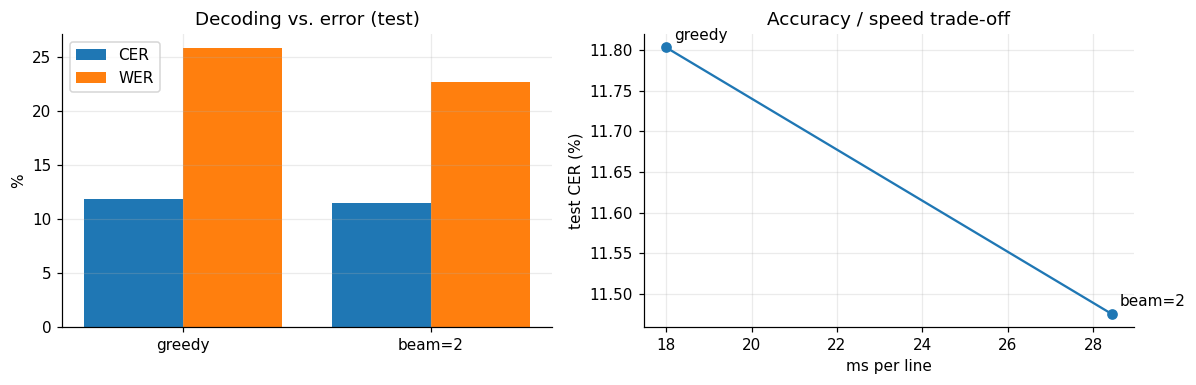

In [21]:
if HAS_LABELS:
    DEC = {}
    val_imgs_main, test_imgs_main = get_images(val_df, MAIN_PREPROC), get_images(test_df, MAIN_PREPROC)
    rows = []
    for nb in CFG["beams"]:
        mv, pv, cv = run_eval(MODEL_FT, val_imgs_main, val_refs, nb, with_conf=True, desc=f"val beam{nb}")
        mt, pt, ct = run_eval(MODEL_FT, test_imgs_main, test_refs, nb, with_conf=True, desc=f"test beam{nb}")
        DEC[nb] = dict(val=(mv, pv, cv), test=(mt, pt, ct))
        rows.append({"decoder": "greedy" if nb == 1 else f"beam={nb}", "num_beams": nb, "val CER (%)": 100 * mv["cer"],
                     "test CER (%)": 100 * mt["cer"], "test WER (%)": 100 * mt["wer"], "test exact (%)": 100 * mt["exact"],
                     "ms / line": 1000 * mt["sec_per_line"]})
    DEC_DF = pd.DataFrame(rows).set_index("decoder"); display(DEC_DF.round(2))
    RESULTS["decoding"] = DEC_DF.reset_index().to_dict("records")

    BEST_BEAMS = int(DEC_DF.sort_values(["val CER (%)", "num_beams"]).iloc[0]["num_beams"])
    print(f"-> BEST_BEAMS = {BEST_BEAMS} (lowest validation CER)")
    RESULTS["meta"]["best_beams"] = BEST_BEAMS
    NAME_FT_BEAM = f"Fine-tuned (beam={BEST_BEAMS})"
    mt, pt, ct = DEC[BEST_BEAMS]["test"]
    if BEST_BEAMS == 1: NAME_FT_BEAM = NAME_FT
    else: record(NAME_FT_BEAM, pt, ct, sec_per_line=mt["sec_per_line"], stage="fine-tuned")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); x = np.arange(len(DEC_DF))
    ax[0].bar(x - .2, DEC_DF["test CER (%)"], .4, label="CER"); ax[0].bar(x + .2, DEC_DF["test WER (%)"], .4, label="WER")
    ax[0].set_xticks(x, DEC_DF.index); ax[0].set(title="Decoding vs. error (test)", ylabel="%"); ax[0].legend()
    ax[1].plot(DEC_DF["ms / line"], DEC_DF["test CER (%)"], "o-")
    for k, (xx, yy) in zip(DEC_DF.index, zip(DEC_DF["ms / line"], DEC_DF["test CER (%)"])): ax[1].annotate(k, (xx, yy), textcoords="offset points", xytext=(5, 5))
    ax[1].set(title="Accuracy / speed trade-off", xlabel="ms per line", ylabel="test CER (%)")
    fig.tight_layout(); save_fig(fig, "decoding_comparison"); plt.show(); save_results()

### 6.5 N-best lexicon rescoring
Beam search returns `nbest_beams` candidate transcriptions per word with their length-normalised log-probabilities. A candidate whose words are all in the **training-transcript lexicon** (or are pure punctuation / contain digits) gets a bonus `λ` added to its score, and the highest total wins. `λ` is tuned on **validation** CER, and `λ = 0` (plain beam search) is one of the options, so it is only used if it helps on validation. Unlike the dictionary post-correction in section 7, it can only pick among strings the model itself proposed, so it rarely breaks correct words.

In [22]:
if HAS_LABELS:
    # ---- 6.5 N-best lexicon rescoring ------------------------------------------------------------
    CORE_RE = re.compile(r"^(\W*)(.*?)(\W*)$")

    def word_core(w):
        return CORE_RE.match(w).group(2).lower()

    LEXICON = {word_core(w) for t in train_refs for w in t.split() if word_core(w)}

    def in_lexicon(text):
        words = text.split()
        if not words:
            return False
        for w in words:
            core = word_core(w)
            if core and not any(ch.isdigit() for ch in core) and core not in LEXICON:
                return False
        return True

    @torch.no_grad()
    def predict_nbest(model, images, num_beams, desc=""):
        """For every image: list of (text, length-normalised log-prob) for the top `num_beams` beams."""
        model.eval(); bs = beam_batch_size(num_beams); out, t_gen = [], 0.0
        for i in tqdm(range(0, len(images), bs), desc=desc, leave=False):
            pv = processor(images=images[i:i + bs], return_tensors="pt").pixel_values.to(device)
            _sync(); t0 = time.perf_counter()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                g = model.generate(pv, num_beams=num_beams, num_return_sequences=num_beams, max_length=MAXLEN, do_sample=False,
                                   early_stopping=True, no_repeat_ngram_size=0, length_penalty=1.0,
                                   output_scores=True, return_dict_in_generate=True)
            _sync(); t_gen += time.perf_counter() - t0
            texts = [norm_ws(t) for t in tokenizer.batch_decode(g.sequences, skip_special_tokens=True)]
            scores = g.sequences_scores.float().cpu().numpy().tolist()
            for j in range(pv.shape[0]):
                a, b = j * num_beams, (j + 1) * num_beams
                out.append(list(zip(texts[a:b], scores[a:b])))
        return out, t_gen / max(1, len(images))

    def rescore(nbest, bonus):
        """Pick the best candidate after adding `bonus` to in-lexicon candidates. Returns (texts, confidences)."""
        texts, confs = [], []
        for cands in nbest:
            best_text, best_total, best_lp = cands[0][0], -1e18, cands[0][1]
            for text, lp in cands:
                total = lp
                if in_lexicon(text):
                    total = lp + bonus
                if total > best_total:
                    best_text, best_total, best_lp = text, total, lp
            texts.append(best_text); confs.append(float(np.exp(best_lp)))
        return texts, confs

    NB = CFG["nbest_beams"]
    NBEST_VAL, _ = predict_nbest(MODEL_FT, val_imgs_main, NB, desc=f"val n-best{NB}")
    NBEST_TEST, NBEST_SEC = predict_nbest(MODEL_FT, test_imgs_main, NB, desc=f"test n-best{NB}")
    oracle = score(val_refs, [next((t for t, _ in c if norm_ws(t) == norm_ws(r)), c[0][0]) for c, r in zip(NBEST_VAL, val_refs)])
    print(f"Oracle (correct word anywhere in the {NB}-best list) val exact = {100*oracle['exact']:.1f}%  <- ceiling for rescoring")

    lex_rows = []
    best_bonus, best_cer = 0.0, None
    for bonus in sorted(CFG["lexicon_bonus_grid"]):
        vt, _ = rescore(NBEST_VAL, bonus); s = score(val_refs, vt)
        lex_rows.append({"bonus": bonus, "val CER (%)": 100 * s["cer"], "val WER (%)": 100 * s["wer"], "val exact (%)": 100 * s["exact"]})
        if best_cer is None or s["cer"] < best_cer - 1e-9:
            best_bonus, best_cer = bonus, s["cer"]
    LEX_DF = pd.DataFrame(lex_rows).set_index("bonus"); display(LEX_DF.round(2))
    print(f"lexicon size {len(LEXICON):,} words | OOV rate of val words vs lexicon "
          f"{100*np.mean([word_core(w) not in LEXICON for t in val_refs for w in t.split() if word_core(w)]):.1f}%")

    LEX_BONUS = best_bonus
    RESULTS["meta"]["lexicon_bonus"] = LEX_BONUS
    RESULTS["val"]["lexicon_rescoring"] = LEX_DF.reset_index().to_dict("records")
    NAME_FT_LEX = None
    beam_val_cer = DEC[BEST_BEAMS]["val"][0]["cer"]
    USE_NBEST = best_cer < beam_val_cer - 1e-9
    if USE_NBEST:
        print(f"-> lexicon rescoring ON (bonus={LEX_BONUS}, {NB}-best)")
        DECODE_DESC = f"{NB}-best + lexicon"
        FINAL_VAL_PREDS, _ = rescore(NBEST_VAL, LEX_BONUS)
        FINAL_TEST_PREDS, FINAL_TEST_CONF = rescore(NBEST_TEST, LEX_BONUS)
        FINAL_SEC = NBEST_SEC
        NAME_FT_LEX = f"Fine-tuned ({DECODE_DESC})"
        record(NAME_FT_LEX, FINAL_TEST_PREDS, FINAL_TEST_CONF, sec_per_line=FINAL_SEC, stage="fine-tuned", lexicon_bonus=LEX_BONUS)
    else:
        print("-> lexicon rescoring did not beat plain beam search on validation; keeping beam search")
        DECODE_DESC = f"beam={BEST_BEAMS}"
        FINAL_VAL_PREDS = DEC[BEST_BEAMS]["val"][1]
        FINAL_TEST_PREDS, FINAL_TEST_CONF = DEC[BEST_BEAMS]["test"][1], DEC[BEST_BEAMS]["test"][2]
        FINAL_SEC = DEC[BEST_BEAMS]["test"][0]["sec_per_line"]
    def decode_model(model, images, desc="decode"):
        """The chosen decoder (beam search, or n-best + lexicon) WITHOUT post-correction. Returns (texts, confidences)."""
        if USE_NBEST:
            nb, _ = predict_nbest(model, images, NB, desc=desc)
            return rescore(nb, LEX_BONUS)
        texts, confs, _ = predict(model, images, BEST_BEAMS, with_conf=True, desc=desc)
        return texts, confs
    save_results()


val n-best4:   0%|          | 0/8 [00:00<?, ?it/s]

test n-best4:   0%|          | 0/8 [00:00<?, ?it/s]

Oracle (correct word anywhere in the 4-best list) val exact = 93.8%  <- ceiling for rescoring


,val CER (%),val WER (%),val exact (%)
bonus,,,
0.00,8.61,17.05,82.81
0.10,9.00,17.05,82.81
0.25,9.00,17.05,82.81
0.50,9.20,17.83,82.03
1.00,9.59,18.60,81.25
2.00,11.94,20.16,79.69
5.00,12.33,20.93,78.91


lexicon size 1,524 words | OOV rate of val words vs lexicon 24.4%
-> lexicon rescoring ON (bonus=0.0, 4-best)
[TEST] Fine-tuned (4-best + lexicon)                           CER  11.31%  WER  22.66%  exact  77.3%


In [23]:
if HAS_LABELS:
    # Post-correction removed: it never beat "no correction" on validation in any run.
    PC = None
    def apply_pc(pc, preds): return list(preds)
    def tune_post_corrector(train_texts, val_refs_, val_preds): return None, pd.DataFrame()
    NAME_FT_FULL = f"Fine-tuned ({DECODE_DESC})"
    record(NAME_FT_FULL, FINAL_TEST_PREDS, FINAL_TEST_CONF, sec_per_line=FINAL_SEC, stage="fine-tuned")
    RESULTS["post_correction"] = dict(chosen=None, note="removed - no gain on validation")
    save_results()

[TEST] Fine-tuned (4-best + lexicon)                           CER  11.31%  WER  22.66%  exact  77.3%


## 8. Ablations — pre-processing and post-correction
Two factors, evaluated on the **test** set with the chosen decoder:

* **Pre-processing:** the main model (trained with `MAIN_PREPROC`) is tested on raw vs. pre-processed input (*inference-only* ablation — note this mismatches train/test for the raw row), **and** (if `run_ablation_retrain`) a second model is **re-trained on the alternative input** (raw, or the best non-raw mode if raw already won) for a clean *train-and-test* comparison.
* **Post-correction:** off vs. on (thresholds re-tuned on validation for each variant).

abl val main model on binarized:   0%|          | 0/4 [00:00<?, ?it/s]

abl test main model on binarized:   0%|          | 0/4 [00:00<?, ?it/s]

abl val main model on raw (inference-only, train/test mismatch):   0%|          | 0/4 [00:00<?, ?it/s]

abl test main model on raw (inference-only, train/test mismatch):   0%|          | 0/4 [00:00<?, ?it/s]

,model trained with,input at test,pre-processing,post-correction,CER (%),WER (%),exact (%)
0,binarized,binarized,yes (binarized),no,11.48,22.66,77.34
1,binarized,raw,no,no,14.43,31.25,68.75


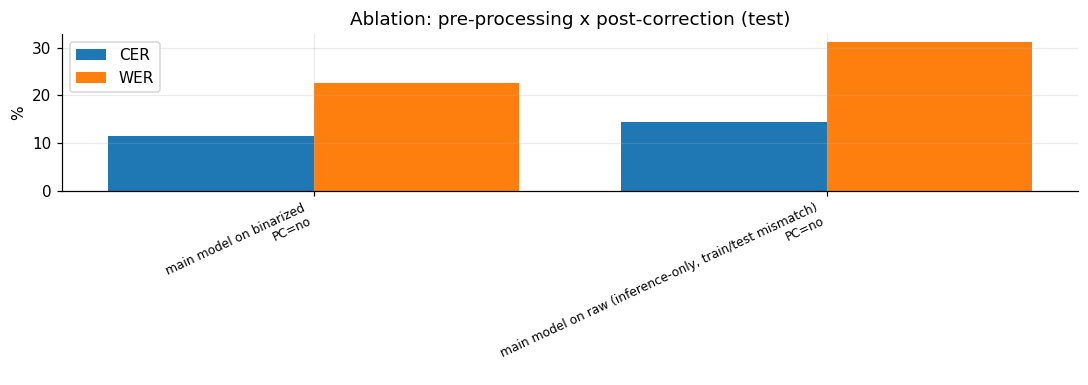

In [24]:
if HAS_LABELS:
    def eval_variant(model, train_mode, test_mode, label):
        """Evaluate one (train-preproc, test-preproc) variant with post-correction off/on. Returns 2 rows."""
        vi, ti = get_images(val_df, test_mode), get_images(test_df, test_mode)
        _, pv, _ = run_eval(model, vi, val_refs, BEST_BEAMS, desc=f"abl val {label}")
        mt, pt, _ = run_eval(model, ti, test_refs, BEST_BEAMS, desc=f"abl test {label}")
        pc, _ = tune_post_corrector(train_refs, val_refs, pv); pt_pc = apply_pc(pc, pt)
        rows = []
        for use_pc, preds in [(False, pt)]:
            s = score(test_refs, preds)
            rows.append({"model trained with": train_mode, "input at test": test_mode, "pre-processing": "no" if test_mode == "raw" else f"yes ({test_mode})",
                         "post-correction": "yes" if use_pc else "no", "CER (%)": 100 * s["cer"], "WER (%)": 100 * s["wer"], "exact (%)": 100 * s["exact"], "variant": label})
        return rows

    ABL = []
    MODEL_FT.cpu(); torch.cuda.empty_cache(); MODEL_FT.to(device)                     # (keeps main model resident; frees cached blocks)
    ABL += eval_variant(MODEL_FT, MAIN_PREPROC, MAIN_PREPROC, f"main model on {MAIN_PREPROC}")
    if MAIN_PREPROC != "raw":
        ABL += eval_variant(MODEL_FT, MAIN_PREPROC, "raw", "main model on raw (inference-only, train/test mismatch)")

    ALT_PREPROC = "raw" if MAIN_PREPROC != "raw" else pre_df.drop(index="raw")["val CER (%)"].idxmin()
    if CFG["run_ablation_retrain"]:
        MODEL_FT.cpu(); torch.cuda.empty_cache()
        MODEL_ALT, HIST_ALT = finetune(CFG["seed"], ALT_PREPROC, tag="ablation")
        ABL += eval_variant(MODEL_ALT, ALT_PREPROC, ALT_PREPROC, f"re-trained on {ALT_PREPROC}")
        RESULTS["meta"]["ablation_alt_val_best_cer"] = float(HIST_ALT.val_cer.min())
        del MODEL_ALT; gc.collect(); torch.cuda.empty_cache(); MODEL_FT.to(device)

    ABL_DF = pd.DataFrame(ABL); display(ABL_DF.drop(columns=["variant"]).round(2))
    RESULTS["ablation"] = ABL_DF.to_dict("records")

    fig, ax = plt.subplots(figsize=(10, 3.6)); labels = [f"{r['variant']}\nPC={r['post-correction']}" for _, r in ABL_DF.iterrows()]
    x = np.arange(len(ABL_DF)); ax.bar(x - .2, ABL_DF["CER (%)"], .4, label="CER"); ax.bar(x + .2, ABL_DF["WER (%)"], .4, label="WER")
    ax.set_xticks(x, labels, rotation=25, ha="right", fontsize=8); ax.set(ylabel="%", title="Ablation: pre-processing x post-correction (test)"); ax.legend()
    fig.tight_layout(); save_fig(fig, "ablation"); plt.show(); save_results()

## 9. RESULTS
Everything below is computed from the stored predictions of the runs above. Only real IAM word images are used.

In [25]:
if HAS_LABELS:
    display(Markdown(
        f"> Data: **IAM** · split: `{CFG['split_mode']}` · "
        f"train/val/test = {len(train_df)}/{len(val_df)}/{len(test_df)} lines · "
        f"forms = {train_df.page.nunique()}/{val_df.page.nunique()}/{test_df.page.nunique()} · "
        f"pre-processing `{MAIN_PREPROC}` · beam={BEST_BEAMS}"
    ))

    # ---- 9.1 summary table with bootstrap CIs ----
    def bootstrap_ci(name, n_boot=2000, seed=0):
        d, l = line_stats(test_refs, PRED_STORE[name]["preds"]); rng = np.random.RandomState(seed)
        idx = rng.randint(0, len(d), (n_boot, len(d))); cer = d[idx].sum(1) / l[idx].sum(1)
        return np.percentile(cer, [2.5, 97.5])

    def paired_bootstrap(a, b, n_boot=2000, seed=0):
        """CER(a) - CER(b) with 95% CI (paired over test lines); p = share of resamples where b is NOT better."""
        da, l = line_stats(test_refs, PRED_STORE[a]["preds"]); db, _ = line_stats(test_refs, PRED_STORE[b]["preds"]); rng = np.random.RandomState(seed)
        idx = rng.randint(0, len(l), (n_boot, len(l))); diff = (da[idx].sum(1) - db[idx].sum(1)) / l[idx].sum(1)
        return diff.mean(), np.percentile(diff, [2.5, 97.5]), float((diff <= 0).mean())

    def results_table(names):
        base = RESULTS["configs"][NAME_BASE]; rows = []
        for n in names:
            m = RESULTS["configs"][n]; lo, hi = bootstrap_ci(n)
            rows.append({"Configuration": n, "CER (%)": 100 * m["cer"], "CER 95% CI": f"[{100*lo:.2f}, {100*hi:.2f}]", "WER (%)": 100 * m["wer"],
                         "Exact-match words (%)": 100 * m["exact"], "CER vs baseline (rel.)": f"{100*(m['cer']-base['cer'])/max(base['cer'], 1e-12):+.1f}%", "ms/line": 1000 * m.get("sec_per_line", np.nan)})
        return pd.DataFrame(rows).set_index("Configuration")

    MAIN3 = [NAME_BASE, NAME_FT, NAME_FT_FULL]
    display(Markdown("### 9.1 Main summary (test set)")); T_MAIN = results_table(MAIN3); display(T_MAIN.round(2))
    ALL_NAMES = [n for n in dict.fromkeys([NAME_BASE, NAME_BASE_PP, NAME_CRNN, NAME_FT, NAME_FT_BEAM, NAME_FT_LEX, NAME_FT_FULL]) if n in RESULTS["configs"]]
    display(Markdown("### All configurations")); T_ALL = results_table(ALL_NAMES); display(T_ALL.round(2))
    T_ALL.reset_index().to_csv(RES / "summary_table.csv", index=False)
    diff, ci, pval = paired_bootstrap(NAME_BASE, NAME_FT_FULL)
    RESULTS["significance"] = dict(comparison=f"{NAME_BASE} minus {NAME_FT_FULL}", cer_diff=diff, ci95=list(ci), p_not_better=pval)
    print(f"Paired bootstrap over test lines: CER(baseline) - CER(final) = {100*diff:+.2f} pp, 95% CI [{100*ci[0]:+.2f}, {100*ci[1]:+.2f}], p(not better)={pval:.4f}")
    save_results()

> Data: **IAM** · split: `page` · train/val/test = 4096/128/128 lines · forms = 426/92/92 · pre-processing `binarized` · beam=2

### 9.1 Main summary (test set)

,CER (%),CER 95% CI,WER (%),Exact-match words (%),CER vs baseline (rel.),ms/line
Configuration,,,,,,
"Pretrained TrOCR (raw input, greedy)",19.34,"[14.38, 25.19]",50.78,59.38,+0.0%,18.84
Fine-tuned (greedy),11.80,"[7.90, 15.77]",25.78,74.22,-39.0%,17.80
Fine-tuned (4-best + lexicon),11.31,"[7.41, 15.46]",22.66,77.34,-41.5%,45.70


### All configurations

,CER (%),CER 95% CI,WER (%),Exact-match words (%),CER vs baseline (rel.),ms/line
Configuration,,,,,,
"Pretrained TrOCR (raw input, greedy)",19.34,"[14.38, 25.19]",50.78,59.38,+0.0%,18.84
"Pretrained TrOCR (+binarized, greedy)",18.52,"[13.72, 24.61]",46.88,60.94,-4.2%,17.89
Fine-tuned (greedy),11.80,"[7.90, 15.77]",25.78,74.22,-39.0%,17.80
Fine-tuned (beam=2),11.48,"[7.51, 15.77]",22.66,77.34,-40.7%,28.43
Fine-tuned (4-best + lexicon),11.31,"[7.41, 15.46]",22.66,77.34,-41.5%,45.70


Paired bootstrap over test lines: CER(baseline) - CER(final) = +8.07 pp, 95% CI [+2.85, +13.74], p(not better)=0.0010


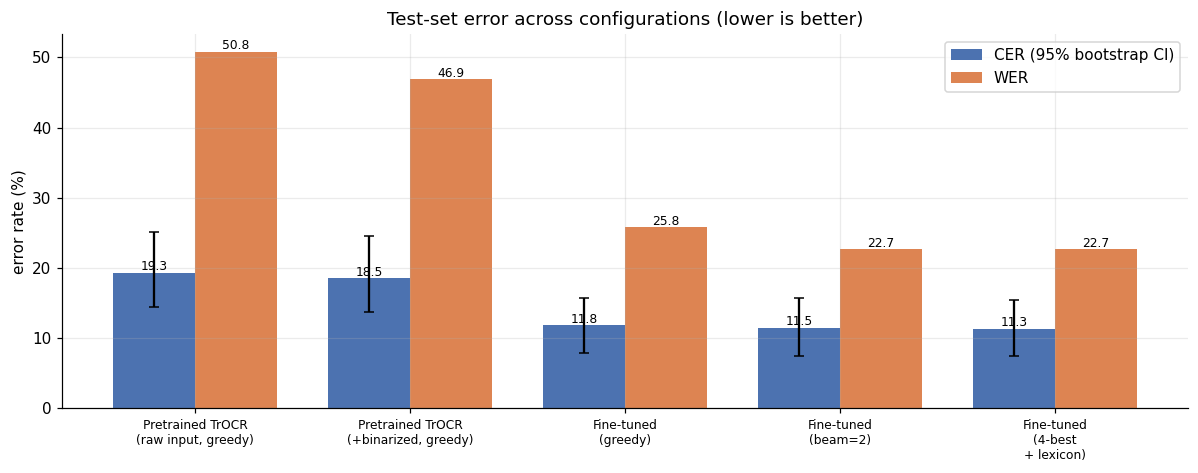

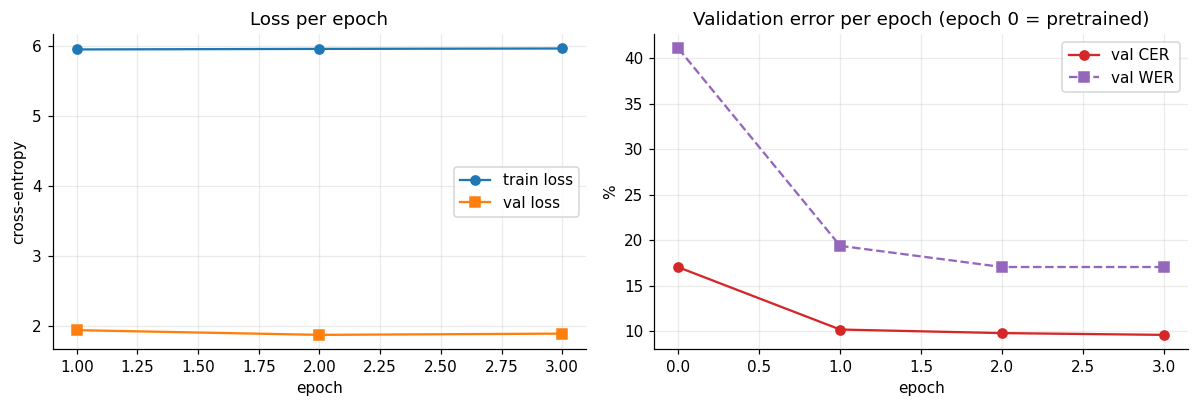

In [26]:
if HAS_LABELS:
    # ---- 9.2 Bar chart: CER / WER across all configurations -------------------------------------
    fig, ax = plt.subplots(figsize=(11, 4.4)); x = np.arange(len(ALL_NAMES)); w = .38
    cer = [100 * RESULTS["configs"][n]["cer"] for n in ALL_NAMES]; wer = [100 * RESULTS["configs"][n]["wer"] for n in ALL_NAMES]
    err = np.array([[100 * RESULTS["configs"][n]["cer"] - 100 * bootstrap_ci(n)[0], 100 * bootstrap_ci(n)[1] - 100 * RESULTS["configs"][n]["cer"]] for n in ALL_NAMES]).T
    b1 = ax.bar(x - w / 2, cer, w, yerr=err, capsize=3, label="CER (95% bootstrap CI)", color="#4C72B0"); b2 = ax.bar(x + w / 2, wer, w, label="WER", color="#DD8452")
    for b in list(b1) + list(b2): ax.text(b.get_x() + b.get_width() / 2, b.get_height() + .4, f"{b.get_height():.1f}", ha="center", fontsize=8)
    ax.set_xticks(x, [n.replace(" (", "\n(").replace(" + ", "\n+ ") for n in ALL_NAMES], fontsize=8); ax.set(ylabel="error rate (%)", title="Test-set error across configurations (lower is better)"); ax.legend()
    fig.tight_layout(); save_fig(fig, "results_bar_cer_wer"); plt.show()

    # ---- 9.3 Training / validation curves -------------------------------------------------------
    H = HIST.copy(); ep0 = pd.DataFrame([dict(stage=0, epoch=0, train_loss=np.nan, val_loss=np.nan, val_cer=BASE_VAL["cer"], val_wer=BASE_VAL["wer"])])
    H = pd.concat([ep0, H], ignore_index=True); s1_end = HIST[HIST.stage == 1].epoch.max()
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(H.epoch, H.train_loss, "o-", label="train loss"); ax[0].plot(H.epoch, H.val_loss, "s-", label="val loss")
    ax[1].plot(H.epoch, 100 * H.val_cer, "o-", color="C3", label="val CER"); ax[1].plot(H.epoch, 100 * H.val_wer, "s--", color="C4", label="val WER")
    for a, t, yl in zip(ax, ["Loss per epoch", "Validation error per epoch (epoch 0 = pretrained)"], ["cross-entropy", "%"]):
        if pd.notna(s1_end): a.axvline(s1_end + .5, color="gray", ls=":", label="stage 1 -> 2 (unfreeze)")
        a.set(title=t, xlabel="epoch", ylabel=yl); a.legend()
    fig.tight_layout(); save_fig(fig, "training_curves"); plt.show()

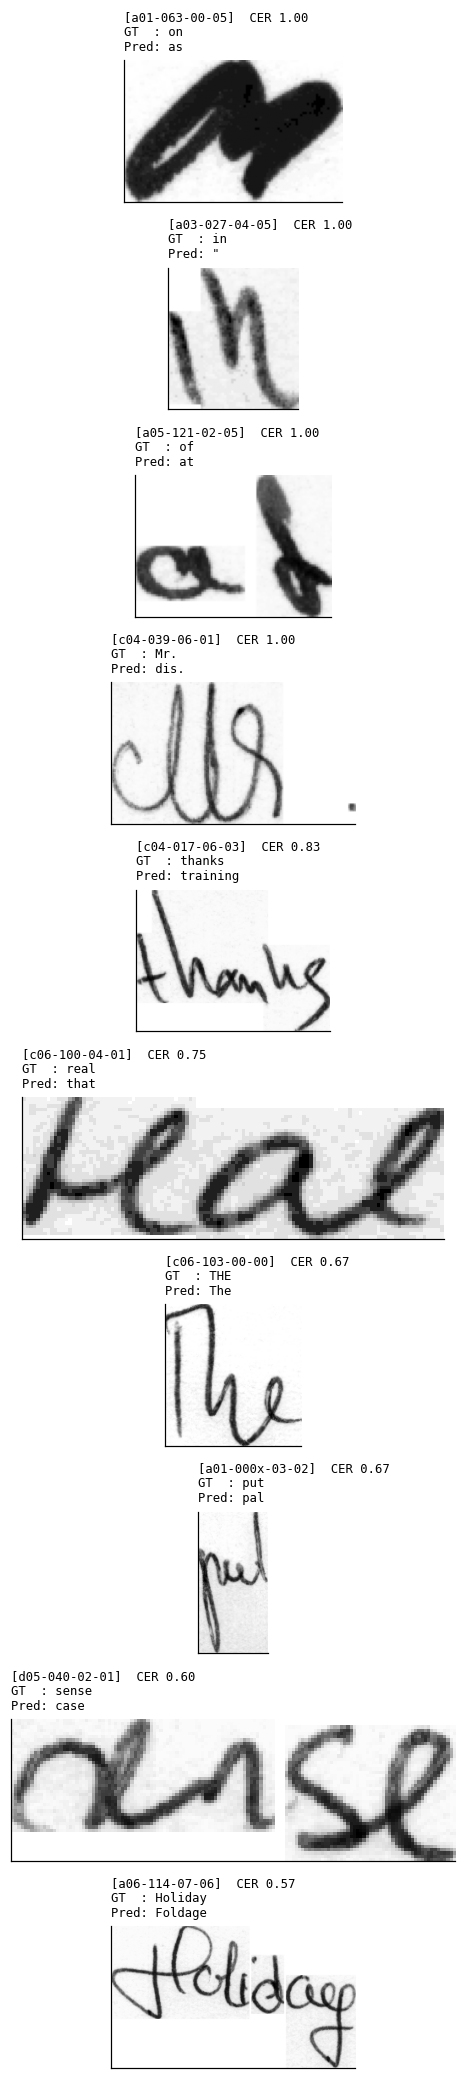

Total char edits on test: 69  (substitutions 52, deletions 12, insertions 5)


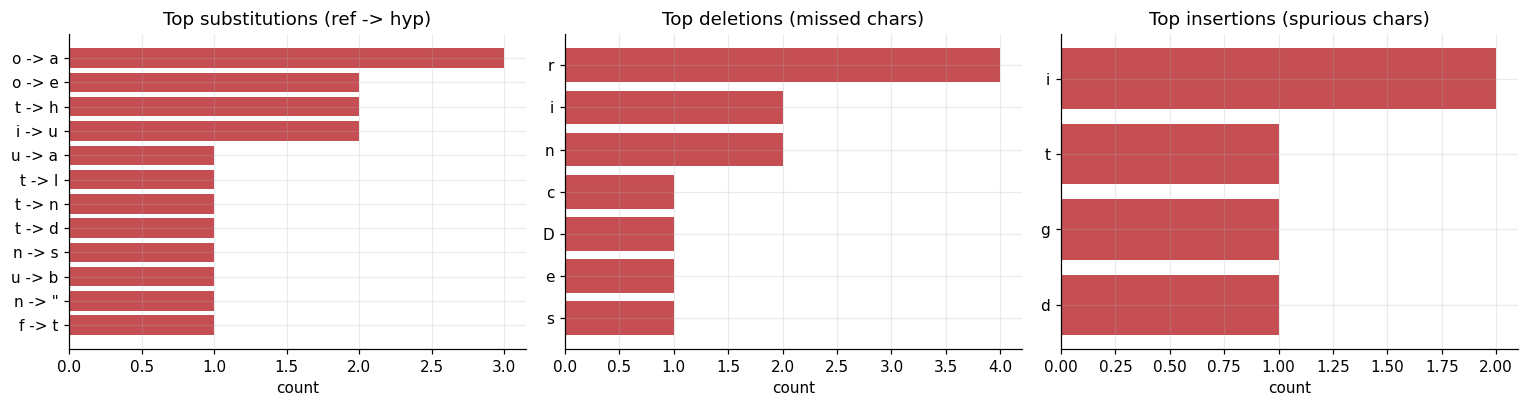

**Hardest characters** (>= 20 occurrences in test references)

,char,occurrences,errors (sub+del),error rate (%)
0,r,40,9,22.5
1,i,39,6,15.4
2,t,55,8,14.5
3,s,37,5,13.5
4,n,38,5,13.2
5,o,38,5,13.2
6,e,73,6,8.2
7,h,31,2,6.5
8,l,26,1,3.8
9,a,42,1,2.4


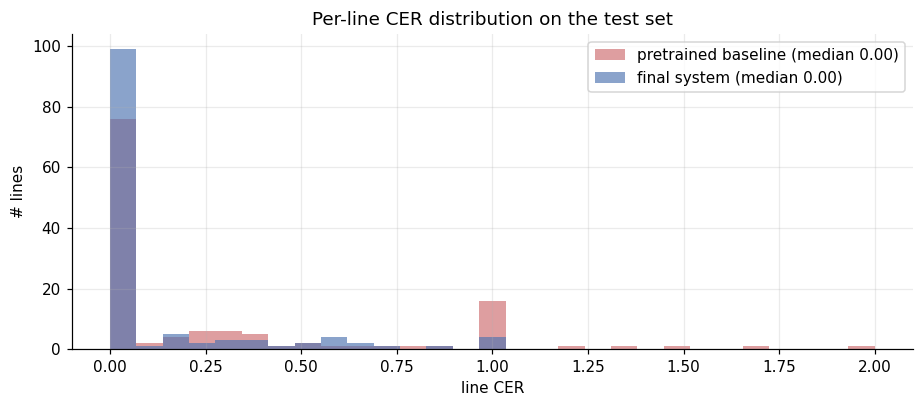

In [27]:
if HAS_LABELS:
    # ---- 9.4 Error analysis: 10 worst lines (final system) ------------------------------------------
    FINAL = NAME_FT_FULL; fin_preds = PRED_STORE[FINAL]["preds"]
    d_fin, l_fin = line_stats(test_refs, fin_preds); line_cer = d_fin / l_fin
    test_imgs_raw = [load_raw(p) for p in test_df.path]

    worst = np.argsort(-line_cer)[:10]
    fig, axes = plt.subplots(len(worst), 1, figsize=(12, 1.9 * len(worst)))
    axes = np.atleast_1d(axes)
    for a, i in zip(axes, worst):
        a.imshow(test_imgs_raw[i], cmap="gray"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
        a.set_title(f"[{test_df.id[i]}]  CER {line_cer[i]:.2f}\nGT  : {test_refs[i]}\nPred: {fin_preds[i]}", fontsize=8, loc="left", family="monospace")
    fig.tight_layout(); save_fig(fig, "worst_10_lines"); plt.show()
    pd.DataFrame({"id": test_df.id[worst].values, "CER": line_cer[worst].round(3), "ground truth": [test_refs[i] for i in worst], "prediction": [fin_preds[i] for i in worst]}).to_csv(RES / "worst_10_lines.csv", index=False)

    # ---- character confusion analysis (Levenshtein alignment) ------------------------------------------
    def align_ops(ref, hyp):
        """Levenshtein alignment -> list of (op, ref_char, hyp_char); op in {eq, sub, del, ins}."""
        n, m = len(ref), len(hyp); D = np.zeros((n + 1, m + 1), dtype=np.int32); D[:, 0] = range(n + 1); D[0, :] = range(m + 1)
        for i in range(1, n + 1):
            for j in range(1, m + 1):
                D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]))
        i, j, ops = n, m, []
        while i > 0 or j > 0:
            if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
                ops.append(("eq" if ref[i - 1] == hyp[j - 1] else "sub", ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
            elif i > 0 and D[i, j] == D[i - 1, j] + 1: ops.append(("del", ref[i - 1], "")); i -= 1
            else: ops.append(("ins", "", hyp[j - 1])); j -= 1
        return ops[::-1]

    vis = lambda c: "<sp>" if c == " " else c
    subs, dels, inss, seen, errs = Counter(), Counter(), Counter(), Counter(), Counter()
    for r, h in zip(test_refs, fin_preds):
        for op, a, b in align_ops(norm_ws(r), norm_ws(h)):
            if op != "ins": seen[a] += 1
            if op == "sub": subs[(a, b)] += 1; errs[a] += 1
            elif op == "del": dels[a] += 1; errs[a] += 1
            elif op == "ins": inss[b] += 1
    tot_ops = sum(subs.values()) + sum(dels.values()) + sum(inss.values())
    print(f"Total char edits on test: {tot_ops}  (substitutions {sum(subs.values())}, deletions {sum(dels.values())}, insertions {sum(inss.values())})")
    RESULTS["error_analysis"] = dict(substitutions=sum(subs.values()), deletions=sum(dels.values()), insertions=sum(inss.values()),
                                     top_substitutions=[[vis(a), vis(b), n] for (a, b), n in subs.most_common(15)],
                                     top_deletions=[[vis(a), n] for a, n in dels.most_common(10)], top_insertions=[[vis(a), n] for a, n in inss.most_common(10)])
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for a, (title, items, lab) in zip(ax, [("Top substitutions (ref -> hyp)", subs.most_common(12), lambda k: f"{vis(k[0])} -> {vis(k[1])}"),
                                           ("Top deletions (missed chars)", dels.most_common(12), vis), ("Top insertions (spurious chars)", inss.most_common(12), vis)]):
        if items: a.barh([lab(k) for k, _ in items][::-1], [n for _, n in items][::-1], color="#C44E52")
        a.set(title=title, xlabel="count")
    fig.tight_layout(); save_fig(fig, "char_confusions"); plt.show()
    hard = pd.DataFrame([{"char": vis(c), "occurrences": seen[c], "errors (sub+del)": errs[c], "error rate (%)": 100 * errs[c] / seen[c]} for c in seen if seen[c] >= 20])
    if len(hard): display(Markdown("**Hardest characters** (>= 20 occurrences in test references)")); display(hard.sort_values("error rate (%)", ascending=False).head(10).round(1).reset_index(drop=True))

    # ---- 9.5 CER distribution ----------------------------------------------------------------------------
    d_b, l_b = line_stats(test_refs, PRED_STORE[NAME_BASE]["preds"]); cer_b = d_b / l_b
    bins = np.linspace(0, max(1.0, line_cer.max(), cer_b.max()), 30)
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    ax.hist(cer_b, bins=bins, alpha=.55, label=f"pretrained baseline (median {np.median(cer_b):.2f})", color="#C44E52")
    ax.hist(line_cer, bins=bins, alpha=.65, label=f"final system (median {np.median(line_cer):.2f})", color="#4C72B0")
    ax.set(title="Per-line CER distribution on the test set", xlabel="line CER", ylabel="# lines"); ax.legend()
    fig.tight_layout(); save_fig(fig, "cer_histogram"); plt.show()
    RESULTS["cer_distribution"] = dict(final_median=float(np.median(line_cer)), final_p90=float(np.percentile(line_cer, 90)), baseline_median=float(np.median(cer_b)), perfect_lines_final=float((line_cer == 0).mean()))

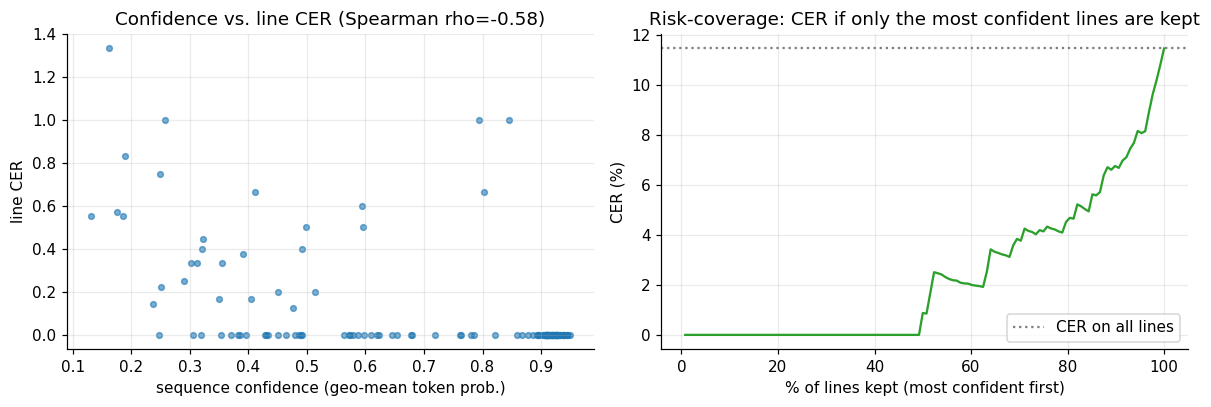

Spearman(confidence, line CER) = -0.578 (p=8.68e-13); CER on the most-confident 50% of lines = 0.87% vs 11.48% on all


In [28]:
if HAS_LABELS:
    # ---- 9.6 Confidence vs. error --------------------------------------------------------------------------
    from scipy.stats import spearmanr
    conf = np.array(DEC[BEST_BEAMS]["test"][2]); d_raw, l_raw = line_stats(test_refs, DEC[BEST_BEAMS]["test"][1]); cer_raw = d_raw / l_raw   # model output BEFORE post-correction
    rho, pv_ = spearmanr(conf, cer_raw)
    order = np.argsort(-conf); cov = np.arange(1, len(order) + 1) / len(order)
    risk = np.cumsum(d_raw[order]) / np.cumsum(l_raw[order])                      # CER of the k most-confident lines
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].scatter(conf, cer_raw, s=14, alpha=.6); ax[0].set(title=f"Confidence vs. line CER (Spearman rho={rho:.2f})", xlabel="sequence confidence (geo-mean token prob.)", ylabel="line CER")
    ax[1].plot(100 * cov, 100 * risk, color="C2"); ax[1].axhline(100 * score(test_refs, DEC[BEST_BEAMS]["test"][1])["cer"], color="gray", ls=":", label="CER on all lines")
    ax[1].set(title="Risk-coverage: CER if only the most confident lines are kept", xlabel="% of lines kept (most confident first)", ylabel="CER (%)"); ax[1].legend()
    fig.tight_layout(); save_fig(fig, "confidence_vs_error"); plt.show()
    RESULTS["confidence"] = dict(spearman_rho=float(rho), p=float(pv_), cer_top50pct=float(100 * risk[len(risk) // 2 - 1]), cer_all=float(100 * risk[-1]))
    print(f"Spearman(confidence, line CER) = {rho:.3f} (p={pv_:.3g}); CER on the most-confident 50% of lines = {100*risk[len(risk)//2-1]:.2f}% vs {100*risk[-1]:.2f}% on all")
    save_results()

### 9.7 Robustness: mean ± std over seeds
The page split is fixed; the **training seed** (initialisation of cross-attention heads, augmentation, data order) changes. Each extra seed re-runs the *full* recipe (two-stage fine-tuning → beam decoding → post-correction re-tuned on that seed's validation predictions). The pretrained baseline is deterministic, so it has no std. With only a handful of test pages, differences smaller than the std are not meaningful.

In [29]:
if HAS_LABELS:
    def run_seed(seed):
        set_all_seeds(seed); MODEL_FT.cpu(); torch.cuda.empty_cache()
        mdl, hist = finetune(seed, MAIN_PREPROC, tag=f"seed{seed}")
        ti, vi = get_images(test_df, MAIN_PREPROC), get_images(val_df, MAIN_PREPROC)
        g = run_eval(mdl, ti, test_refs, 1, desc=f"seed{seed} greedy")[0]
        b, pb, _ = run_eval(mdl, ti, test_refs, BEST_BEAMS, desc=f"seed{seed} beam")
        pv = decode_model(mdl, vi, desc=f"seed{seed} val")[0]; pf = decode_model(mdl, ti, desc=f"seed{seed} test")[0]
        pc, _ = tune_post_corrector(train_refs, val_refs, pv); f = score(test_refs, apply_pc(pc, pf))
        del mdl; gc.collect(); torch.cuda.empty_cache(); MODEL_FT.to(device)
        return {"seed": seed, NAME_FT: g, NAME_FT_BEAM: b, NAME_FT_FULL: f}

    SEED_RUNS = [{"seed": CFG["seed"], NAME_FT: RESULTS["configs"][NAME_FT], NAME_FT_BEAM: RESULTS["configs"].get(NAME_FT_BEAM, RESULTS["configs"][NAME_FT]), NAME_FT_FULL: RESULTS["configs"][NAME_FT_FULL]}]
    if CFG["run_multiseed"]:
        for s in CFG["extra_seeds"]:
            SEED_RUNS.append(run_seed(s)); print(f"seed {s} done")
    rows = []
    for n in dict.fromkeys([NAME_FT, NAME_FT_BEAM, NAME_FT_FULL]):
        vals = {k: np.array([r[n][k] for r in SEED_RUNS]) * 100 for k in ("cer", "wer", "exact")}
        sd = lambda v: v.std(ddof=1) if len(v) > 1 else float("nan")
        rows.append({"Configuration": n, "CER (%) mean ± std": f"{vals['cer'].mean():.2f} ± {sd(vals['cer']):.2f}", "WER (%) mean ± std": f"{vals['wer'].mean():.2f} ± {sd(vals['wer']):.2f}",
                     "Exact (%) mean ± std": f"{vals['exact'].mean():.1f} ± {sd(vals['exact']):.1f}", "seeds": len(SEED_RUNS), "per-seed CER (%)": ", ".join(f"{x:.2f}" for x in vals["cer"])})
    b = RESULTS["configs"][NAME_BASE]
    rows.insert(0, {"Configuration": NAME_BASE + "  [deterministic]", "CER (%) mean ± std": f"{100*b['cer']:.2f}", "WER (%) mean ± std": f"{100*b['wer']:.2f}", "Exact (%) mean ± std": f"{100*b['exact']:.1f}", "seeds": "-", "per-seed CER (%)": "-"})
    SEED_DF = pd.DataFrame(rows).set_index("Configuration"); display(SEED_DF)
    RESULTS["seeds"] = [{"seed": r["seed"], **{n: r[n] for n in (NAME_FT, NAME_FT_BEAM, NAME_FT_FULL)}} for r in SEED_RUNS]
    if len(SEED_RUNS) < 3: print(f"NOTE: only {len(SEED_RUNS)} seed(s) were run; enable run_multiseed / extra_seeds for >= 3.")
    SEED_DF.reset_index().to_csv(RES / "seed_summary.csv", index=False); save_results()

,CER (%) mean ± std,WER (%) mean ± std,Exact (%) mean ± std,seeds,per-seed CER (%)
Configuration,,,,,
"Pretrained TrOCR (raw input, greedy) [deterministic]",19.34,50.78,59.4,-,-
Fine-tuned (greedy),11.80 ± nan,25.78 ± nan,74.2 ± nan,1,11.80
Fine-tuned (beam=2),11.48 ± nan,22.66 ± nan,77.3 ± nan,1,11.48
Fine-tuned (4-best + lexicon),11.31 ± nan,22.66 ± nan,77.3 ± nan,1,11.31


NOTE: only 1 seed(s) were run; enable run_multiseed / extra_seeds for >= 3.


In [30]:
if HAS_LABELS:
    # ---- save predictions of every config for later inspection --------------------------------------------------
    pred_df = test_df[["id", "page", "text"]].rename(columns={"text": "ground_truth"}).copy()
    for n, v in PRED_STORE.items(): pred_df[n] = v["preds"]
    pred_df.to_csv(RES / "test_predictions.csv", index=False); print("saved", RES / "test_predictions.csv")

saved /kaggle/working/results_iam/test_predictions.csv


## 10. Semantic search over the digitised archive
**Documents.** Consecutive word crops of a page are grouped into passages (`passage_lines` word crops each), built from the **OCR output of the final system** — i.e. what the archive would actually contain. By default only the held-out **test pages** are indexed (`search_scope="test"`), because OCR on training pages would be optimistic; set `"all"` to index everything.

**Retrieval.** `all-MiniLM-L6-v2` sentence embeddings (L2-normalised) in a FAISS inner-product index (= cosine similarity) vs. a **BM25** keyword baseline on the same OCR text.

**Two evaluations**
* **(A) User-defined query set** — edit `QUERY_SET` below: a natural-language query plus `keywords`; a passage counts as *relevant* if its **ground-truth** text contains any keyword. Queries are deliberately worded differently from the archive text, to test meaning-based retrieval. The defaults are *illustrative guesses* about the IAM content — the cell prints how many relevant passages each query has, and drops queries that have none. Replace them with your own pairs.
* **(B) OCR-noise robustness** — query = one ground-truth line, target = the passage containing it; compared on the OCR index vs. a ground-truth-text index, which isolates how much recognition errors hurt retrieval.

Metrics: **Recall@k** = share of queries with ≥1 relevant passage in the top-k; **MRR** = mean reciprocal rank of the first relevant passage.

In [31]:
if HAS_LABELS:
    from sentence_transformers import SentenceTransformer
    from rank_bm25 import BM25Okapi

    # Topic queries for IAM; keyword labels are weak relevance proxies.
    # Freeze queries before comparing systems. Replace with human-labelled relevance
    # judgements for a rigorous semantic retrieval benchmark.
    QUERY_SET = [
        dict(query="government decisions and political debate", keywords=["government", "minister", "parliament", "political"]),
        dict(query="education and learning at school", keywords=["school", "education", "teacher", "student"]),
        dict(query="employment and economic activity", keywords=["work", "employment", "business", "economic"]),
        dict(query="family life and relationships", keywords=["family", "mother", "father", "children"]),
        dict(query="travel and transportation", keywords=["train", "railway", "car", "travel"]),
    ]

    st_model = SentenceTransformer(CFG["minilm_local"] or CFG["minilm_id"], device=str(device))

    def final_ocr(df):
        """Final system (best beam + post-correction) on arbitrary lines of the archive."""
        p, _ = decode_model(MODEL_FT, get_images(df, MAIN_PREPROC), desc="OCR")
        return apply_pc(PC, p)

    scope_df = test_df if CFG["search_scope"] == "test" else DF.copy()
    if CFG["search_scope"] == "test": OCR_TEXT = dict(zip(test_df.id, PRED_STORE[NAME_FT_FULL]["preds"]))
    else:
        OCR_TEXT = dict(zip(scope_df.id, final_ocr(scope_df))); print("NOTE: scope='all' -> OCR on training pages is optimistic (model saw them).")
    GT_TEXT = dict(zip(scope_df.id, scope_df.text))

    def build_passages(df, text_map, k):
        docs = []
        for page, g in df.groupby("page"):
            ids = sorted(g.id)
            for s in range(0, len(ids), k):
                chunk = ids[s:s + k]; docs.append(dict(doc_id=len(docs), page=page, first=chunk[0], last=chunk[-1], line_ids=chunk, text=" ".join(text_map[i] for i in chunk)))
        return docs

    DOCS_OCR = build_passages(scope_df, OCR_TEXT, CFG["passage_lines"]); DOCS_GT = build_passages(scope_df, GT_TEXT, CFG["passage_lines"])
    print(f"{len(DOCS_OCR)} passages ({CFG['passage_lines']} lines each) from {scope_df.page.nunique()} pages")

    def embed(texts): return st_model.encode(texts, convert_to_numpy=True, normalize_embeddings=True, batch_size=64, show_progress_bar=False).astype("float32")
    def make_faiss(docs):
        E = embed([d["text"] for d in docs]); idx = faiss.IndexFlatIP(E.shape[1]); idx.add(E); return idx
    tok = lambda s: re.findall(r"\w+", s.lower())
    def make_bm25(docs): return BM25Okapi([tok(d["text"]) or ["_"] for d in docs])

    IDX_OCR, IDX_GT = make_faiss(DOCS_OCR), make_faiss(DOCS_GT); BM_OCR, BM_GT = make_bm25(DOCS_OCR), make_bm25(DOCS_GT)

    def rank_semantic(index, q): _, I = index.search(embed([q]), index.ntotal); return I[0]
    def rank_bm25(bm, q): return np.argsort(-bm.get_scores(tok(q)), kind="stable")
    def sem_search(q, k=3): D, I = IDX_OCR.search(embed([q]), min(k, IDX_OCR.ntotal)); return list(zip(I[0], D[0]))

    def rank_metrics(rankings, relevant):
        rankings, relevant = list(rankings), list(relevant)
        if len(rankings) != len(relevant) or not rankings or any(not r for r in relevant):
            raise ValueError("Need equally sized, non-empty rankings and relevance sets")
        def recall(k):
            return float(np.mean([len(set(rk[:k]) & rel) / len(rel) for rk, rel in zip(rankings, relevant)]))
        rr = [next((1.0 / (j + 1) for j, d in enumerate(rk) if d in rel), 0.0)
              for rk, rel in zip(rankings, relevant)]
        return dict(recall_at_1=recall(1), recall_at_5=recall(5), mrr=float(np.mean(rr)), n_queries=len(rr))

92 passages (30 lines each) from 92 pages


In [32]:
if HAS_LABELS:
    # ---- 10.1 Five example queries -> top-3 results with scores --------------------------------------------------------
    qs_valid = []
    for q in QUERY_SET:
        rel = {d["doc_id"] for d in DOCS_GT if any(re.search(r"\b" + re.escape(kw.lower()) + r"\b", d["text"].lower()) for kw in q["keywords"])}
        print(f"{len(rel):3d} keyword-matched passages | {q['query']}")
        if rel: qs_valid.append(dict(q, relevant=rel))
    if len(qs_valid) < len(QUERY_SET): print(f"-> dropped {len(QUERY_SET)-len(qs_valid)} query(ies) with no relevant passage in the indexed pages (edit QUERY_SET).")

    for q in qs_valid[:5]:
        rows = [{"rank": r + 1, "score (cosine)": round(float(s), 3), "pages/lines": f"{DOCS_OCR[i]['first']} .. {DOCS_OCR[i]['last']}",
                 "relevant": "✓" if i in q["relevant"] else "✗", "OCR text": DOCS_OCR[i]["text"][:150]} for r, (i, s) in enumerate(sem_search(q["query"], 3))]
        display(Markdown(f"**Query:** _{q['query']}_")); display(pd.DataFrame(rows).set_index("rank"))

  0 keyword-matched passages | government decisions and political debate
  0 keyword-matched passages | education and learning at school
  0 keyword-matched passages | employment and economic activity
  0 keyword-matched passages | family life and relationships
  0 keyword-matched passages | travel and transportation
-> dropped 5 query(ies) with no relevant passage in the indexed pages (edit QUERY_SET).


No valid user-defined queries -> evaluation (A) skipped.


,n_queries,recall_at_1,recall_at_5,mrr
B_line_query_semantic_OCR,92.0,0.576,0.783,0.669
B_line_query_BM25_OCR,92.0,0.598,0.750,0.666
B_line_query_semantic_GT,92.0,0.728,0.870,0.795
B_line_query_BM25_GT,92.0,0.761,0.902,0.821


(chance level for Recall@5 with 92 passages ~ 0.05 if one passage were relevant)


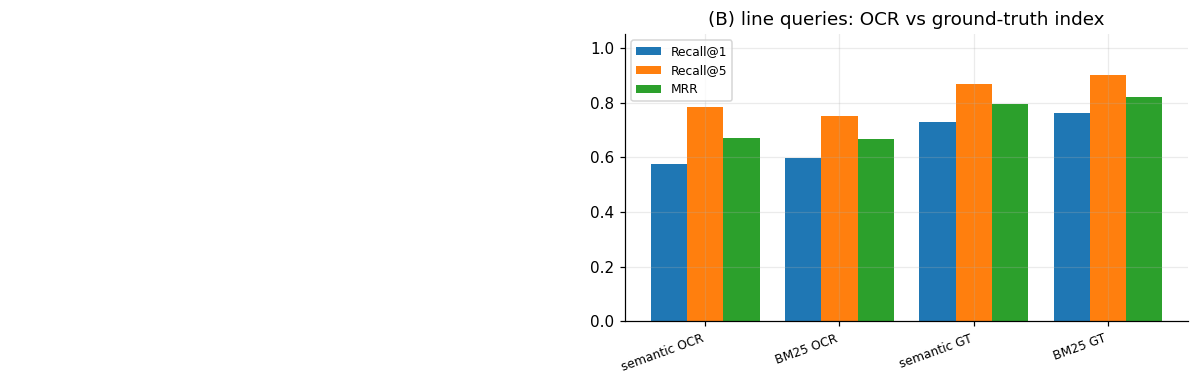

In [33]:
if HAS_LABELS:
    # ---- 10.2 Evaluation (A) user-defined queries, semantic vs BM25 -----------------------------------------------------
    res_search = {}
    if qs_valid:
        rel = [q["relevant"] for q in qs_valid]
        res_search["A_user_queries_semantic_OCR"] = rank_metrics([rank_semantic(IDX_OCR, q["query"]) for q in qs_valid], rel)
        res_search["A_user_queries_BM25_OCR"]     = rank_metrics([rank_bm25(BM_OCR, q["query"]) for q in qs_valid], rel)
        res_search["A_user_queries_semantic_GT"]  = rank_metrics([rank_semantic(IDX_GT, q["query"]) for q in qs_valid], rel)
        res_search["A_user_queries_BM25_GT"]      = rank_metrics([rank_bm25(BM_GT, q["query"]) for q in qs_valid], rel)
    else: print("No valid user-defined queries -> evaluation (A) skipped.")

    # (B) OCR-noise robustness: query = a ground-truth line, target = its passage
    rng = np.random.RandomState(0); line2doc = {lid: d["doc_id"] for d in DOCS_GT for lid in d["line_ids"]}
    qB, relB = [], []
    for d in DOCS_GT: lid = rng.choice(d["line_ids"]); qB.append(GT_TEXT[lid]); relB.append({d["doc_id"]})
    res_search["B_line_query_semantic_OCR"] = rank_metrics([rank_semantic(IDX_OCR, q) for q in qB], relB)
    res_search["B_line_query_BM25_OCR"]     = rank_metrics([rank_bm25(BM_OCR, q) for q in qB], relB)
    res_search["B_line_query_semantic_GT"]  = rank_metrics([rank_semantic(IDX_GT, q) for q in qB], relB)
    res_search["B_line_query_BM25_GT"]      = rank_metrics([rank_bm25(BM_GT, q) for q in qB], relB)

    S_DF = pd.DataFrame(res_search).T[["n_queries", "recall_at_1", "recall_at_5", "mrr"]]; display(S_DF.round(3))
    RESULTS["search"] = dict(metrics=res_search, n_passages=len(DOCS_OCR), scope=CFG["search_scope"], relevance_method="A: whole-word keyword proxy; B: source-passage lookup", random_recall_at_5=min(1.0, 5 / len(DOCS_OCR)),
                             queries=[dict(query=q["query"], keywords=q["keywords"], n_relevant=len(q["relevant"])) for q in qs_valid])
    print(f"(chance level for Recall@5 with {len(DOCS_OCR)} passages ~ {min(1.0, 5/len(DOCS_OCR)):.2f} if one passage were relevant)")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for a, pref, ttl in zip(ax, ["A_user_queries", "B_line_query"], ["(A) user-defined queries (OCR index)", "(B) line queries: OCR vs ground-truth index"]):
        keys = [k for k in res_search if k.startswith(pref) and (pref == "B_line_query" or k.endswith("OCR"))]
        if not keys: a.axis("off"); continue
        x = np.arange(len(keys)); w = .27
        for j, (met, lab) in enumerate([("recall_at_1", "Recall@1"), ("recall_at_5", "Recall@5"), ("mrr", "MRR")]):
            a.bar(x + (j - 1) * w, [res_search[k][met] for k in keys], w, label=lab)
        a.set_xticks(x, [k.replace(pref + "_", "").replace("_", " ") for k in keys], rotation=20, ha="right", fontsize=8); a.set(ylim=(0, 1.05), title=ttl); a.legend(fontsize=8)
    fig.tight_layout(); save_fig(fig, "search_metrics"); plt.show(); save_results()

## 11. Word recognition demo
Recognise real held-out word crops directly. No artificial page composition or page segmentation.

In [34]:
if HAS_LABELS:
    demo_df = test_df.head(5)
    raw_ocr, conf_ocr = decode_model(MODEL_FT, get_images(demo_df, MAIN_PREPROC), desc='word demo')
    fixed_ocr = apply_pc(PC, raw_ocr)
    display(pd.DataFrame({'id': demo_df.id.tolist(), 'ground truth': demo_df.text.tolist(), 'OCR': raw_ocr, 'corrected': fixed_ocr}))
    RESULTS['demo'] = score(demo_df.text.tolist(), fixed_ocr)
    save_results()

word demo:   0%|          | 0/1 [00:00<?, ?it/s]

,id,ground truth,OCR,corrected
0,a01-000x-01-07,be,be,be
1,a01-000x-03-02,put,pal,pal
2,a01-011-06-00,Mr.,Mr.,Mr.
3,a01-014u-05-03,chief,chief,chief
4,a01-014u-05-05,",",",",","


In [35]:
if HAS_LABELS:
    print('Semantic search over IAM word passages is available in section 10.')

Semantic search over IAM word passages is available in section 10.


## 12. Conclusion (auto-generated from this run's numbers)
The text below is assembled by code from `results.json` values, so it always matches the experiments that were actually run (a different dataset copy or seed will change the wording and numbers automatically). It is also saved as `results/conclusion.md`.

In [36]:
if HAS_LABELS:
    # ---- 12. IAM conclusion, generated only from measured results ----
    def pct(x): return f"{100*x:.2f}%"
    cf = RESULTS["configs"]
    b, ft, full = [cf[k] for k in (NAME_BASE, NAME_FT, NAME_FT_FULL)]
    L = ["# IAM handwriting recognition and semantic search", "",
         f"Dataset: {len(DF):,} retained IAM words; {DF.page.nunique()} forms; writer identities unavailable.",
         f"Split protocol: {CFG['split_mode']}; no form or word IDs shared across splits; writer overlap is unknown.",
         f"Model initialisation: {TROCR_SRC}.",
         f"Training/validation/test lines: {len(train_df)}/{len(val_df)}/{len(test_df)}.", "",
         "| Configuration | CER | WER | Exact-match words |",
         "|---|---:|---:|---:|"]
    for name in MAIN3:
        m = cf[name]
        L.append(f"| {name} | {pct(m['cer'])} | {pct(m['wer'])} | {pct(m['exact'])} |")
    L += ["", f"Fine-tuning changes greedy CER from {pct(b['cer'])} to {pct(ft['cer'])}.",
          f"Validation selected preprocessing `{MAIN_PREPROC}` and beam width {BEST_BEAMS}.",
          f"Post-correction validation choice: {RESULTS['post_correction']['chosen']}."]
    if b['cer'] > 0:
        L.append(f"Final system relative CER reduction versus baseline: {100*(b['cer']-full['cer'])/b['cer']:+.2f}%.")
    ci = RESULTS['significance']['ci95']
    L.append(f"Paired line-bootstrap 95% CI for baseline minus final CER: [{100*ci[0]:+.2f}, {100*ci[1]:+.2f}] percentage points.")
    L += ["", "## Retrieval", "",
          "Topic relevance uses whole-word keyword matches: these are weak labels, not human semantic judgements.",
          "Line-query retrieval measures source-passage recovery and OCR-noise sensitivity, not independent semantic understanding."]
    for name, m in RESULTS['search']['metrics'].items():
        L.append(f"- {name}: queries={m['n_queries']}, Recall@1={m['recall_at_1']:.3f}, Recall@5={m['recall_at_5']:.3f}, MRR={m['mrr']:.3f}.")
    L += ["", "## Limitations", "",
          "- IAM is modern handwriting; this run does not establish historical-archive performance.",
          "- A custom form split is not directly comparable with published official-split IAM results.",
          "- Only readable, matched lines with segmentation status 'ok' are used; consult the saved split manifest and exclusion counts.",
          "- Word-level bootstrap intervals ignore within-form and within-writer correlation and may be too narrow.",
          "- The CRNN is trained from scratch; TrOCR benefits from external pretraining, so this is not an equal-pretraining comparison.",
          "- The demo uses actual word crops; no page segmentation is evaluated.",
          "- FAST_DEBUG results are smoke tests and must not be presented as full-dataset results."]
    CONCLUSION_MD = "\n".join(L)
    display(Markdown(CONCLUSION_MD))
    (RES / "conclusion.md").write_text(CONCLUSION_MD)
    save_results()

# IAM handwriting recognition and semantic search

Dataset: 38,305 retained IAM words; 610 forms; writer identities unavailable.
Split protocol: page; no form or word IDs shared across splits; writer overlap is unknown.
Model initialisation: microsoft/trocr-base-stage1.
Training/validation/test lines: 4096/128/128.

| Configuration | CER | WER | Exact-match words |
|---|---:|---:|---:|
| Pretrained TrOCR (raw input, greedy) | 19.34% | 50.78% | 59.38% |
| Fine-tuned (greedy) | 11.80% | 25.78% | 74.22% |
| Fine-tuned (4-best + lexicon) | 11.31% | 22.66% | 77.34% |

Fine-tuning changes greedy CER from 19.34% to 11.80%.
Validation selected preprocessing `binarized` and beam width 2.
Post-correction validation choice: None.
Final system relative CER reduction versus baseline: +41.53%.
Paired line-bootstrap 95% CI for baseline minus final CER: [+2.85, +13.74] percentage points.

## Retrieval

Topic relevance uses whole-word keyword matches: these are weak labels, not human semantic judgements.
Line-query retrieval measures source-passage recovery and OCR-noise sensitivity, not independent semantic understanding.
- B_line_query_semantic_OCR: queries=92, Recall@1=0.576, Recall@5=0.783, MRR=0.669.
- B_line_query_BM25_OCR: queries=92, Recall@1=0.598, Recall@5=0.750, MRR=0.666.
- B_line_query_semantic_GT: queries=92, Recall@1=0.728, Recall@5=0.870, MRR=0.795.
- B_line_query_BM25_GT: queries=92, Recall@1=0.761, Recall@5=0.902, MRR=0.821.

## Limitations

- IAM is modern handwriting; this run does not establish historical-archive performance.
- A custom form split is not directly comparable with published official-split IAM results.
- Only readable, matched lines with segmentation status 'ok' are used; consult the saved split manifest and exclusion counts.
- Word-level bootstrap intervals ignore within-form and within-writer correlation and may be too narrow.
- The CRNN is trained from scratch; TrOCR benefits from external pretraining, so this is not an equal-pretraining comparison.
- The demo uses actual word crops; no page segmentation is evaluated.
- FAST_DEBUG results are smoke tests and must not be presented as full-dataset results.

In [37]:
if HAS_LABELS:
    # ---- final bookkeeping --------------------------------------------------------------------------------------------------
    save_results()
    print("Reproducibility: seeds =", [CFG["seed"]] + CFG["extra_seeds"], "| split_seed =", CFG["split_seed"], "| data =", RESULTS["meta"]["data_source"])
    print("Versions:", VERSIONS)
    print("\nFiles written to", RES)
    for p in sorted(RES.rglob("*")):
        if p.is_file() and "trocr_finetuned" not in str(p): print(f"  {str(p.relative_to(RES)):45s} {p.stat().st_size/1024:9.1f} KB")

Reproducibility: seeds = [42] | split_seed = 0 | data = IAM words
Versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'jiwer': '4.0.0', 'sentence-transformers': '5.7.0', 'faiss': '1.15.1', 'opencv': '4.14.0', 'scikit-image': '0.25.2', 'rapidfuzz': '3.14.6', 'rank-bm25': '0.2.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.3', 'Pillow': '13.0.0'}

Files written to /kaggle/working/results_iam
  best_val_cer.txt                                    0.0 KB
  conclusion.md                                       2.1 KB
  figures/ablation.png                               49.3 KB
  figures/cer_histogram.png                          36.3 KB
  figures/char_confusions.png                        45.2 KB
  figures/confidence_vs_error.png                    82.8 KB
  figures/dataset_stats.png                          35.2 KB
  figures/decoding_comparison.png                    60.2 KB
  figures/preprocessing_before_after.png            258.5 KB
  figures/results_

## 13. References

[1] M. Li et al., "TrOCR: Transformer-based Optical Character Recognition with Pre-trained Models," arXiv:2109.10282, 2021.

[2] U. Marti and H. Bunke, "The IAM-database: an English sentence database for offline handwriting recognition," *International Journal on Document Analysis and Recognition (IJDAR)*, vol. 5, 2002.

[3] V. Lavrenko, T. Rath, and R. Manmatha, "Holistic Word Recognition for Handwritten Historical Documents," *DIAL*, 2004 (Washington dataset); A. Fischer et al., "Lexicon-free handwritten word spotting using character HMMs," *Pattern Recognition Letters*, 2012.

[4] B. Shi, X. Bai, and C. Yao, "An End-to-End Trainable Neural Network for Image-Based Sequence Recognition and Its Application to Scene Text Recognition," arXiv:1507.05717.

[5] A. Graves et al., "Connectionist Temporal Classification: Labelling Unsegmented Sequence Data with Recurrent Neural Networks," *ICML*, 2006.

[6] H. Scheidl, S. Fiel, and R. Sablatnig, "Word Beam Search: A Connectionist Temporal Classification Decoding Algorithm," *ICFHR*, 2018.

[7] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks," *EMNLP*, 2019, arXiv:1908.10084.

[8] J. Puigcerver, "Are Multidimensional Recurrent Layers Really Necessary for Handwritten Text Recognition?," *ICDAR*, 2017.

[9] B. Kiessling, "Kraken — a universal text recognizer for the humanities," *Digital Humanities (DH)*, 2019.

[10] HTR-United: <https://htr-united.github.io>

*Additional tools/methods used in this notebook (not in the original reference list):*

[11] J. Sauvola and M. Pietikäinen, "Adaptive document image binarization," *Pattern Recognition*, 33(2), 2000.

[12] J. Johnson, M. Douze, and H. Jégou, "Billion-scale similarity search with GPUs," *IEEE Transactions on Big Data*, 2021 (arXiv:1702.08734) — FAISS.

[13] S. Robertson and H. Zaragoza, "The Probabilistic Relevance Framework: BM25 and Beyond," *Foundations and Trends in Information Retrieval*, 3(4), 2009.

[14] W. Wang et al., "MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers," arXiv:2002.10957, 2020 (basis of `all-MiniLM-L6-v2`).

In [38]:
   !ls -lh /kaggle/working/results_iam/trocr_finetuned

total 1.5G
-rw-r--r-- 1 root root 1.5K Nov  2 15:42 config.json
-rw-r--r-- 1 root root  175 Nov  2 15:42 generation_config.json
-rw-r--r-- 1 root root 446K Nov  2 15:42 merges.txt
-rw------- 1 root root 1.5G Nov  2 15:42 model.safetensors
-rw-r--r-- 1 root root  390 Nov  2 15:42 preprocessor_config.json
-rw-r--r-- 1 root root  957 Nov  2 15:42 special_tokens_map.json
-rw-r--r-- 1 root root 1.3K Nov  2 15:42 tokenizer_config.json
-rw-r--r-- 1 root root 976K Nov  2 15:42 vocab.json


In [39]:
# import kagglehub
# kagglehub.model_upload(
#     "athuljohnn/trocr-iam-words/transformers/default",
#     "/kaggle/working/results_iam/trocr_finetuned",
#     license_name="Apache 2.0",
# )

Uploading Model https://kaggle.com/models/athuljohnn/trocr-iam-words/transformers/default ...
Model 'trocr-iam-words' does not exist or access is forbidden for user 'athuljohnn'. Creating or handling Model...
Starting upload for file /kaggle/working/results_iam/trocr_finetuned/merges.txt


Uploading: 100%|██████████| 456k/456k [00:00<00:00, 1.39MB/s]

Upload successful: /kaggle/working/results_iam/trocr_finetuned/merges.txt (446KB)
Starting upload for file /kaggle/working/results_iam/trocr_finetuned/model.safetensors



Uploading: 100%|██████████| 1.54G/1.54G [00:17<00:00, 88.0MB/s]

Upload successful: /kaggle/working/results_iam/trocr_finetuned/model.safetensors (1GB)
Starting upload for file /kaggle/working/results_iam/trocr_finetuned/tokenizer_config.json



Uploading: 100%|██████████| 1.26k/1.26k [00:00<00:00, 4.13kB/s]

... (8 outputs left out)

Upload successful: /kaggle/working/results_iam/trocr_finetuned/vocab.json (976KB)
Starting upload for file /kaggle/working/results_iam/trocr_finetuned/generation_config.json



Uploading: 100%|██████████| 175/175 [00:00<00:00, 601B/s]

Upload successful: /kaggle/working/results_iam/trocr_finetuned/generation_config.json (175B)


Your model instance has been created.
Files are being processed...
See at: https://kaggle.com/models/athuljohnn/trocr-iam-words/transformers/default


In [42]:
# big_test = DF[DF.page.isin(groups["test"])].sample(n=800, random_state=0).reset_index(drop=True)
# big_refs = big_test.text.tolist()
# m_g, _, _ = run_eval(MODEL_FT, get_images(big_test, MAIN_PREPROC), big_refs, 1, desc="big test greedy")
# m_b, _, _ = run_eval(MODEL_FT, get_images(big_test, MAIN_PREPROC), big_refs, 2, desc="big test beam2")
# for name, m in [("greedy", m_g), ("beam=2", m_b)]:
#     print(f"{name}: CER {100*m['cer']:.2f}%  WER {100*m['wer']:.2f}%  exact {100*m['exact']:.1f}%  (n={m['n']})")

big test greedy:   0%|          | 0/25 [00:00<?, ?it/s]

big test beam2:   0%|          | 0/25 [00:00<?, ?it/s]

greedy: CER 9.74%  WER 18.78%  exact 81.4%  (n=800)
beam=2: CER 9.20%  WER 17.41%  exact 82.8%  (n=800)
